# TUGAS 1 — AUDIT DATA DAN EXPLORATORY DATA ANALYSIS
**203012520032 - Seagata Ade Pratama Barus** <br>
***Visualisasi Data Lanjut (CAK7AGB4)***

## 0 - _Ouverture_

### Library of ~~Ruina~~

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
import warnings
import matplotlib.colors as mcolors
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

warnings.filterwarnings("ignore")

### Theme

In [ ]:
furina_bubble = {
    "abyss_black":     "#12161E",  # Added as the starting shade
    "ousia_navy":      "#152C5B",  # Blue 1
    "royal_blue":      "#2C50A5",  # Blue 2
    "slate_blue":      "#5883C4",  # Blue 3
    "pneuma_cyan":     "#3EA9E8",  # Blue 4
    "bubble_teal":     "#96fffe",  # Blue 5
    "ice_white":       "#FAFCFF",  # Blue 6 (Pale/White)
    "firefly_green":   "#7AE5AC",
    "deep_pink":       "#C73B6F",
    "elysian_pink":    "#FF6EB4",
    "herta_purple":    "#6B528D",
    "december_grey":   "#8A96A8",
    "bubblegum":       "#a5ece7",
    "soft_bg":         "#F4F7FB",
    "extra":           "#ffffff"
}

categorical_palette = [
    furina_bubble["pneuma_cyan"],
    furina_bubble["ousia_navy"],
    furina_bubble["elysian_pink"],
    furina_bubble["slate_blue"],
    furina_bubble["firefly_green"],
    furina_bubble["bubblegum"],
    furina_bubble["herta_purple"],
    furina_bubble["abyss_black"]
]

days_palette = [
    furina_bubble["herta_purple"],
    furina_bubble["pneuma_cyan"],
    furina_bubble["bubblegum"],
    furina_bubble["elysian_pink"],
    furina_bubble["firefly_green"],
    furina_bubble["slate_blue"],
    furina_bubble["royal_blue"]
]

months_palette = [
    furina_bubble["extra"],
    furina_bubble["ousia_navy"],
    furina_bubble["royal_blue"],
    furina_bubble["slate_blue"],
    furina_bubble["pneuma_cyan"],
    furina_bubble["bubble_teal"],
    furina_bubble["bubblegum"],
    furina_bubble["firefly_green"],
    furina_bubble["elysian_pink"],
    furina_bubble["deep_pink"],
    furina_bubble["herta_purple"],
    furina_bubble["december_grey"]
]

mpl.rcParams.update({
    "figure.facecolor":  furina_bubble["soft_bg"],
    "axes.facecolor":    furina_bubble["soft_bg"],
    "savefig.facecolor": furina_bubble["soft_bg"],

    "text.color":        furina_bubble["abyss_black"],
    "axes.labelcolor":   furina_bubble["abyss_black"],
    "xtick.color":       furina_bubble["abyss_black"],
    "ytick.color":       furina_bubble["abyss_black"],
    "axes.edgecolor":    furina_bubble["abyss_black"],

    "axes.spines.top":   False,
    "axes.spines.right": False,

    "axes.grid":         True,
    "grid.color":        furina_bubble["abyss_black"],
    "grid.alpha":        0.08,
    "grid.linestyle":    "-",

    "axes.prop_cycle":   mpl.cycler(color=categorical_palette),
    "lines.linewidth":   2.0,

    "font.family":       "sans-serif",
    "font.sans-serif":   ["Liberation Sans", "DejaVu Sans", "Arial", "sans-serif"]
})

sns.set_palette(sns.color_palette(categorical_palette))
divergent_cmap = LinearSegmentedColormap.from_list( "PinkWhiteBlue",
    [   furina_bubble["deep_pink"],    # -1.0
        furina_bubble["elysian_pink"], # -0.5
        furina_bubble["ice_white"],    #  0.0
        furina_bubble["pneuma_cyan"],  #  0.5
        furina_bubble["ousia_navy"]    #  1.0
    ]
)

palette_list = list(furina_bubble.values())
sns.set_palette(palette_list)

### Load Dataset


In [ ]:
df = pd.read_csv('203012520032_layanan.csv')
df.head().sample(5)

,id_transaksi,tanggal,cabang,kategori_produk,kanal,jumlah_unit,harga_satuan,diskon_persen,rating_pelanggan,waktu_proses_menit,status,total_transaksi
3,TRX001446,2025-11-25,Garut,Elektronik,Offline,4,1924300.0,10,5.0,27.1,Selesai,6927480.0
4,TRX003596,2025-06-07,Cimahi,Perawatan Diri,Offline,1,60800.0,0,4.0,65.0,Selesai,60800.0
1,TRX001126,2025-05-23,Cirebon,Peralatan Rumah,Offline,5,368600.0,0,3.0,31.6,Selesai,1843000.0
0,TRX000675,2025-08-25,Sumedang,Makanan Kering,Online,1,24700.0,20,3.0,8.9,Selesai,19760.0
2,TRX002510,2025-08-01,Sumedang,Makanan Kering,on-line,3,26700.0,20,4.0,19.9,Pending,64080.0


In [ ]:
df.shape[0]

3765

## A — Audit kualitas data

### Trimming

Trimming whitespace at the beginning and the end of string

In [ ]:
#Copied & modified from: https://stackoverflow.com/a/45355563
df = df.apply(lambda x: x.str.strip() if x.dtype == "str" else x)

###
___

### Inconsistencies

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3765 entries, 0 to 3764
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_transaksi        3765 non-null   str    
 1   tanggal             3765 non-null   str    
 2   cabang              3765 non-null   str    
 3   kategori_produk     3765 non-null   str    
 4   kanal               3765 non-null   str    
 5   jumlah_unit         3765 non-null   int64  
 6   harga_satuan        3765 non-null   float64
 7   diskon_persen       3765 non-null   int64  
 8   rating_pelanggan    3629 non-null   float64
 9   waktu_proses_menit  3765 non-null   float64
 10  status              3765 non-null   str    
 11  total_transaksi     3765 non-null   float64
dtypes: float64(4), int64(2), str(6)
memory usage: 353.1 KB


In [ ]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_transaksi,3765,3699,TRX002772,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tanggal,3765,615,2025-08-19,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cabang,3765,8,Cimahi,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kategori_produk,3765,5,Perawatan Diri,956,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kanal,3765,9,Online,1850,NaN,NaN,NaN,NaN,NaN,NaN,NaN
jumlah_unit,3765.0,NaN,NaN,NaN,3.888977,8.880234,0.0,2.0,3.0,4.0,118.0
harga_satuan,3765.0,NaN,NaN,NaN,327859.028632,597432.337838,23.0,28700.0,68400.0,305700.0,2317100.0
diskon_persen,3765.0,NaN,NaN,NaN,4.525896,6.967526,0.0,0.0,0.0,10.0,20.0
rating_pelanggan,3629.0,NaN,NaN,NaN,7.675944,18.849027,1.0,3.0,4.0,4.0,99.0
waktu_proses_menit,3765.0,NaN,NaN,NaN,52.259894,534.572867,-22.5,12.5,25.8,40.6,17411.8


As can be seen above, id_transaksi count is lower than its unique value & the freq = 2; therefore it must contain duplicates, it will be addressed in the next step.

Let's skip it and just start by converting the date back to datetime from string first

To avoid issue with some entry using ISO8601 format; we will be use 'mixed', change the format to follow Indonesian Time Format(dd-mm-yyyy)

In [ ]:
df['tanggal'] = pd.to_datetime(df['tanggal'], format="mixed")
df['tanggal'].dt.strftime('%d/%m/%Y')

0       25/08/2025
1       23/05/2025
2       01/08/2025
3       25/11/2025
4       07/06/2025
           ...    
3760    17/07/2025
3761    17/09/2025
3762    07/09/2025
3763    27/06/2025
3764    04/12/2025
Name: tanggal, Length: 3765, dtype: str

___

In [ ]:
df['cabang'].describe()

count       3765
unique         8
top       Cimahi
freq         491
Name: cabang, dtype: object

In [ ]:
df["cabang"].unique()

<StringArray>
[   'Sumedang',     'Cirebon',       'Garut',      'Cimahi', 'Tasikmalaya',
      'Bekasi',     'Bandung',       'Bogor']
Length: 8, dtype: str

'cabang' is fine

___

In [ ]:
df['kanal'].describe()

count       3765
unique         9
top       Online
freq        1850
Name: kanal, dtype: object

In [ ]:
df["kanal"].unique()

<StringArray>
[ 'Online', 'Offline', 'on-line', 'offline', 'OFFLINE',  'ONLINE',  'online',
  'Daring',  'Luring']
Length: 9, dtype: str

The format here is a mess, we can convert it to one-hot encoding by changing it to binary "is_online" True or False, but it would be more readable by Indonesian if we kept it as Kanal with only 2 unique value of Online & Offline

In [ ]:
kanal = {'online':'Online', 'ONLINE':'Online', 'on-line':'Online', 'Daring':'Online',
           'offline':'Offline', 'OFFLINE':'Offline', 'Luring':'Offline'}
df['kanal'] = df['kanal'].replace(kanal)

In [ ]:
df["kanal"].unique()

<StringArray>
['Online', 'Offline']
Length: 2, dtype: str

___

In [ ]:
df['kategori_produk'].describe()

count               3765
unique                 5
top       Perawatan Diri
freq                 956
Name: kategori_produk, dtype: object

In [ ]:
df["kategori_produk"].unique()

<StringArray>
['Makanan Kering', 'Peralatan Rumah', 'Elektronik', 'Perawatan Diri',
 'Aksesori']
Length: 5, dtype: str

'kategori_produk' seems fine

___

In [ ]:
df['jumlah_unit'].describe()

count    3765.000000
mean        3.888977
std         8.880234
min         0.000000
25%         2.000000
50%         3.000000
75%         4.000000
max       118.000000
Name: jumlah_unit, dtype: float64

In [ ]:
df['jumlah_unit'].unique()

array([  1,   5,   3,   4,   2,   0,  70,  63,  77, 116,  74,  88,  52,
        91,  92, 103,  72,  78, 112,  64,  71, 117,  69, 113,  99,  68,
        84,  80,  47, 109,  83,  79,  85,  87,  95,  40, 118,  82,  75,
        89,  56])

Who buy 0 item?

In [ ]:
print(df[df['jumlah_unit'] == 0].shape[0],"People")

14 People


This will be fixed on the further section

___

In [ ]:
df['harga_satuan'].describe().map(lambda x: f'{x:.4f}')

count       3765.0000
mean      327859.0286
std       597432.3378
min           23.0000
25%        28700.0000
50%        68400.0000
75%       305700.0000
max      2317100.0000
Name: harga_satuan, dtype: str

There is a weird thing going on in the min, time to investigate that by binning the Q1

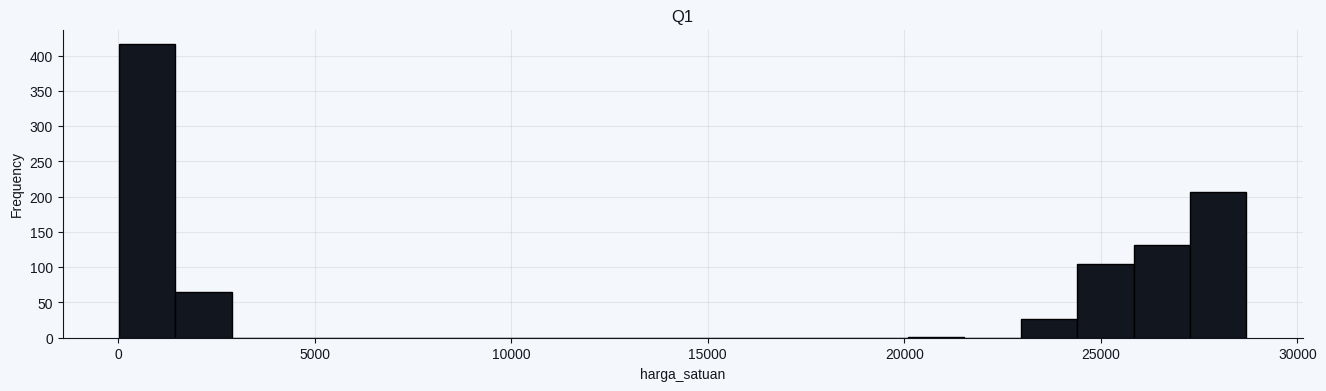

In [ ]:
q1 = df['harga_satuan'].quantile(0.25)
subset = df.loc[df['harga_satuan'] <= q1, 'harga_satuan']

plt.figure(figsize=(16, 4))
plt.hist(subset, bins=20, edgecolor='black')
plt.title('Q1')
plt.xlabel('harga_satuan')
plt.ylabel('Frequency')
plt.show()

Something is going on below 2.5k

In [ ]:
df[df['harga_satuan'] < 2500].sample(10)

,id_transaksi,tanggal,cabang,kategori_produk,kanal,jumlah_unit,harga_satuan,diskon_persen,rating_pelanggan,waktu_proses_menit,status,total_transaksi
2097,TRX000533,2025-10-31,Bandung,Makanan Kering,Online,2,26.8,0,NaN,8.1,Selesai,53.60
559,TRX000207,2025-04-18,Bandung,Perawatan Diri,Online,3,74.6,0,4.0,15.4,Selesai,223.80
851,TRX003417,2025-04-27,Bandung,Peralatan Rumah,Offline,3,272.8,10,5.0,43.8,Selesai,736.56
1810,TRX002850,2025-09-22,Bandung,Makanan Kering,Online,3,30.6,5,NaN,8.6,Selesai,87.21
2027,TRX000891,2025-11-12,Bandung,Perawatan Diri,Offline,5,64.6,0,4.0,42.2,Selesai,323.00
719,TRX002830,2025-06-15,Bandung,Makanan Kering,Online,5,27.5,0,3.0,8.3,Selesai,137.50
297,TRX003405,2025-11-21,Bandung,Perawatan Diri,Online,5,65.9,10,5.0,16.6,Selesai,296.55
814,TRX001150,2025-04-02,Bandung,Makanan Kering,Online,5,24.6,0,4.0,34.2,Selesai,278.00
708,TRX001925,2025-09-19,Bandung,Perawatan Diri,Online,5,69.3,0,4.0,14.2,Batal,346.50
234,TRX001487,2025-10-31,Bandung,Perawatan Diri,Online,1,67.5,20,4.0,14.2,Selesai,54.00


Because by default Rupiah is safe to be used in binary, the fact that 'harga_satuan' is using float can be assumed that a certain branch shorten 000 into comma i.e. 67.1(k) rupiah

In [ ]:
df['cabang'][df['harga_satuan'] < 2500].value_counts()

cabang
Bandung    481
Name: count, dtype: int64

Yup, Bandung use that format for sure, lets change the 'harga_satuan' and also add it at the 'total_transaksi'

In [ ]:
df.loc[(df['cabang'] == 'Bandung'), 'harga_satuan'] *= 1000
df.loc[(df['cabang'] == 'Bandung'), 'total_transaksi'] *= 1000

In [ ]:
df[df['cabang'] == 'Bandung'].sample(5)

,id_transaksi,tanggal,cabang,kategori_produk,kanal,jumlah_unit,harga_satuan,diskon_persen,rating_pelanggan,waktu_proses_menit,status,total_transaksi
3617,TRX001448,2025-09-15,Bandung,Elektronik,Offline,4,1654100.0,0,4.0,16.8,Selesai,6616400.0
3673,TRX001905,2025-03-08,Bandung,Makanan Kering,Online,2,27500.0,20,4.0,26.1,Selesai,44000.0
335,TRX003650,2025-07-18,Bandung,Makanan Kering,Online,1,25700.0,0,4.0,37.7,Selesai,25700.0
1945,TRX001266,2025-03-24,Bandung,Aksesori,Online,3,84200.0,0,3.0,26.5,Selesai,252600.0
70,TRX002105,2025-02-28,Bandung,Peralatan Rumah,Offline,1,351100.0,0,5.0,38.7,Selesai,351100.0


___

In [ ]:
df['diskon_persen'].describe()

count    3765.000000
mean        4.525896
std         6.967526
min         0.000000
25%         0.000000
50%         0.000000
75%        10.000000
max        20.000000
Name: diskon_persen, dtype: float64

In [ ]:
df['diskon_persen'].unique()

array([20,  0, 10,  5, 15])

'diskon_persen' seems fine

___

In [ ]:
df['rating_pelanggan'].describe()

count    3629.000000
mean        7.675944
std        18.849027
min         1.000000
25%         3.000000
50%         4.000000
75%         4.000000
max        99.000000
Name: rating_pelanggan, dtype: float64

In [ ]:
df['rating_pelanggan'].unique()

array([ 3.,  4.,  5., 99.,  2., nan,  1.])

In [ ]:
df[df['rating_pelanggan'] > 5].sample(5)

,id_transaksi,tanggal,cabang,kategori_produk,kanal,jumlah_unit,harga_satuan,diskon_persen,rating_pelanggan,waktu_proses_menit,status,total_transaksi
3267,TRX000935,2025-04-29,Sumedang,Aksesori,Online,2,94900.0,10,99.0,39.0,Selesai,170820.0
1760,TRX000133,2025-05-17,Bandung,Makanan Kering,Offline,4,25600.0,0,99.0,30.6,Selesai,102400.0
1299,TRX003335,2025-10-01,Cimahi,Aksesori,Online,4,94100.0,10,99.0,10.7,Selesai,338760.0
1483,TRX000195,2025-06-16,Bekasi,Aksesori,Online,5,85500.0,15,99.0,-21.9,Selesai,363375.0
1305,TRX002881,2025-08-01,Cirebon,Aksesori,Online,3,80600.0,5,99.0,9.9,Selesai,229710.0


Nice... some people seems to like the product & services way too much that they rate it almost 20 times higher than the maximum rating (1-5), also ther are missing values, we will fix it in later step, averaging it would skew the dataset and tamper the distribution, so no we will not averaging it.

___

In [ ]:
df['waktu_proses_menit'].describe()

count     3765.000000
mean        52.259894
std        534.572867
min        -22.500000
25%         12.500000
50%         25.800000
75%         40.600000
max      17411.800000
Name: waktu_proses_menit, dtype: float64

In [ ]:
df[df['waktu_proses_menit'] < 1].sample(5)

,id_transaksi,tanggal,cabang,kategori_produk,kanal,jumlah_unit,harga_satuan,diskon_persen,rating_pelanggan,waktu_proses_menit,status,total_transaksi
833,TRX002407,2025-12-28,Bekasi,Perawatan Diri,Offline,2,63300.0,0,4.0,-15.8,Selesai,126600.0
158,TRX003602,2025-07-28,Bogor,Aksesori,Online,4,88300.0,0,3.0,-17.4,Selesai,353200.0
3198,TRX002569,2025-03-04,Bandung,Elektronik,Offline,1,1764000.0,0,4.0,-11.8,Selesai,1764000.0
2387,TRX000266,2025-05-10,Tasikmalaya,Perawatan Diri,Offline,1,65700.0,0,4.0,-22.5,Selesai,65700.0
2893,TRX000599,2025-01-08,Bandung,Perawatan Diri,Online,4,58600.0,0,4.0,-11.5,Selesai,234400.0


Safe to assume that it is just a typo of adding dash(-) to it, so lets just remove the dash so it is not treated as negative.

In [ ]:
df['waktu_proses_menit'] = df['waktu_proses_menit'].astype(str).str.replace('-', '', regex=False).astype(float)

In [ ]:
df[df['waktu_proses_menit'] < 1].shape[0]

0

Also... the max is way off the chart, it will be fixed in later step

___

In [ ]:
df['status'].describe()

count        3765
unique          3
top       Selesai
freq         3382
Name: status, dtype: object

In [ ]:
df['status'].unique()

<StringArray>
['Selesai', 'Pending', 'Batal']
Length: 3, dtype: str

Nothing's wrong on 'status'

___

In [ ]:
df['total_transaksi'].describe().map(lambda x: f'{x:.4f}')

count         3765.0000
mean       1336594.4372
std        5322890.6827
min          18640.0000
25%         109120.0000
50%         261450.0000
75%         948480.0000
max      151883720.0000
Name: total_transaksi, dtype: str

The max is weird... We will fix it in later section after done with 'jumlah_unit'

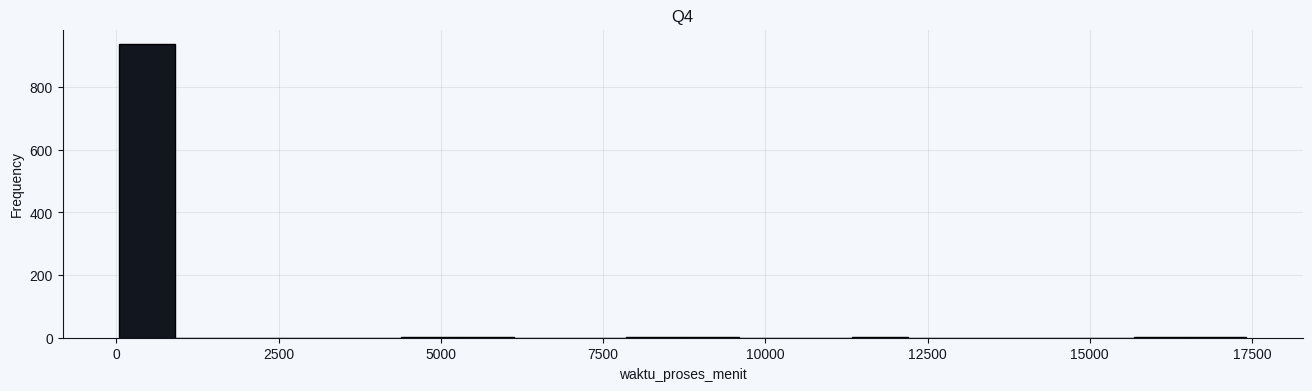

In [ ]:
q4 = df['waktu_proses_menit'].quantile(0.75)
subset = df.loc[df['waktu_proses_menit'] >= q4, 'waktu_proses_menit']

plt.figure(figsize=(16, 4))
plt.hist(subset, bins=20, edgecolor='black')
plt.title('Q4')
plt.xlabel('waktu_proses_menit')
plt.ylabel('Frequency')
plt.show()

In [ ]:
df['waktu_proses_menit'].describe().map(lambda x: f'{x:.4f}')

count     3765.0000
mean        52.4225
std        534.5569
min          3.2000
25%         12.6000
50%         25.8000
75%         40.6000
max      17411.8000
Name: waktu_proses_menit, dtype: str

In [ ]:
df[df['waktu_proses_menit'] > 360].sample(5)

,id_transaksi,tanggal,cabang,kategori_produk,kanal,jumlah_unit,harga_satuan,diskon_persen,rating_pelanggan,waktu_proses_menit,status,total_transaksi
129,TRX000166,2025-12-02,Cimahi,Perawatan Diri,Offline,5,52200.0,10,4.0,8588.1,Selesai,234900.0
2928,TRX003544,2025-09-10,Tasikmalaya,Perawatan Diri,Online,4,60800.0,0,5.0,5912.1,Selesai,243200.0
222,TRX001529,2025-03-24,Bogor,Perawatan Diri,Online,3,66200.0,0,5.0,9065.0,Selesai,198600.0
2458,TRX003514,2025-06-21,Sumedang,Elektronik,Offline,1,2012200.0,15,NaN,8810.9,Selesai,1710370.0
2282,TRX001529,2025-03-24,Bogor,Perawatan Diri,Online,3,66200.0,0,5.0,9065.0,Selesai,198600.0


TBH this is not much of a problem, there might be some issue with the payment system or a monetary issue,  it didnt mater too much in the grand scheme of thing and will be analyzed on B part, so it can be left unattended; my theory were:
1. If it's online it might be Cash On Delivery type of payment
2. If it's offline it might be waiting for the delivery or for the company check to do the payment

###
___

### Duplicates

Since the only identifiable and reliable duplicate to be checked are based on the id, only 'id_transaksi' will be used. As can be seen by the freq = 2 & total entry is bigger than the amount of unique value; thereafter can be inferenced that there are duplicates in it

In [ ]:
dup_id = df[df.duplicated(subset='id_transaksi', keep=False)]
n_conflict = dup_id.drop_duplicates().groupby('id_transaksi').size().gt(1).sum()
n_conflict_id = df[df.duplicated(subset='id_transaksi', keep=False) & ~df.duplicated(keep=False)]
print(f'ID Duplikat dengan value Identik: {df.duplicated().sum()}')
print(f'ID Duplikat dengan value berbeda: {n_conflict}')

ID Duplikat dengan value Identik: 39
ID Duplikat dengan value berbeda: 27


#### ID Duplikat dengan value Identik

In [ ]:
dup_id.sort_values('id_transaksi').head(6)

,id_transaksi,tanggal,cabang,kategori_produk,kanal,jumlah_unit,harga_satuan,diskon_persen,rating_pelanggan,waktu_proses_menit,status,total_transaksi
1927,TRX000018,2025-07-17,Bandung,Makanan Kering,Online,1,24600.0,5,4.0,6.0,Selesai,23370.0
480,TRX000018,2025-07-17,Bandung,Makanan Kering,Online,1,24600.0,5,4.0,6.0,Selesai,23370.0
1018,TRX000067,2025-04-27,Garut,Peralatan Rumah,Online,1,271600.0,0,4.0,4.1,Batal,271600.0
813,TRX000067,2025-04-27,Garut,Peralatan Rumah,Online,1,271600.0,0,4.0,4.1,Batal,271600.0
1267,TRX000070,2025-09-11,Bandung,Aksesori,Online,2,92900.0,5,3.0,5.7,Selesai,176510.0
2196,TRX000070,2025-09-11,Bandung,Aksesori,Online,2,92900.0,5,3.0,5.7,Selesai,176510.0


#### ID Duplikat dengan value berbeda

In [ ]:
n_conflict_id.sort_values(by='id_transaksi', kind='stable').head(6)

,id_transaksi,tanggal,cabang,kategori_produk,kanal,jumlah_unit,harga_satuan,diskon_persen,rating_pelanggan,waktu_proses_menit,status,total_transaksi
1840,TRX000347,2025-06-16,Cirebon,Peralatan Rumah,Online,2,289800.0,20,5.0,15.7,Selesai,463680.0
3199,TRX000347,2025-06-16,Cirebon,Peralatan Rumah,Online,2,289800.0,20,5.0,16.8,Selesai,463680.0
796,TRX000395,2025-08-05,Tasikmalaya,Perawatan Diri,Online,1,62200.0,0,5.0,6.5,Selesai,62200.0
932,TRX000395,2025-05-08,Tasikmalaya,Perawatan Diri,Online,1,62200.0,0,5.0,6.3,Selesai,62200.0
241,TRX001143,2025-10-04,Tasikmalaya,Perawatan Diri,Offline,2,68200.0,20,4.0,40.5,Batal,109120.0
1790,TRX001143,2025-10-04,Tasikmalaya,Perawatan Diri,Offline,2,68200.0,20,4.0,41.7,Batal,109120.0


Safe to assume that the later entered value is the right one, and the previous one contains typo in it; Therefore we shall purge the duplicates...

In [ ]:
df= df.drop(n_conflict_id.index)
df= df.drop_duplicates()

In [ ]:
dup_id = df[df.duplicated(subset='id_transaksi', keep=False)]
n_conflict = dup_id.drop_duplicates().groupby('id_transaksi').size().gt(1).sum()
n_conflict_id = df[df.duplicated(subset='id_transaksi', keep=False) & ~df.duplicated(keep=False)]
print(f'ID Duplikat dengan value Identik: {df.duplicated().sum()}')
print(f'ID Duplikat dengan value berbeda: {n_conflict}')

ID Duplikat dengan value Identik: 0
ID Duplikat dengan value berbeda: 0


In [ ]:
feature_cols = df.columns.drop("id_transaksi")

duplicates = df[df.duplicated(subset=feature_cols, keep=False)].sort_values(
    by=list(feature_cols)
)

In [ ]:
duplicates.head(10)

,id_transaksi,tanggal,cabang,kategori_produk,kanal,jumlah_unit,harga_satuan,diskon_persen,rating_pelanggan,waktu_proses_menit,status,total_transaksi


No duplicates with the same values with different 'id_transaksi'

###
___

### Impossible Value

Continuing the issue from Inconsistencies

In [ ]:
df[df['jumlah_unit'] == 0].sample(5)

,id_transaksi,tanggal,cabang,kategori_produk,kanal,jumlah_unit,harga_satuan,diskon_persen,rating_pelanggan,waktu_proses_menit,status,total_transaksi
2797,TRX002726,2025-04-29,Tasikmalaya,Peralatan Rumah,Offline,0,337400.0,0,4.0,51.5,Selesai,1349600.0
998,TRX003686,2025-11-24,Garut,Perawatan Diri,Online,0,61500.0,20,4.0,3.6,Batal,98400.0
2943,TRX003386,2025-10-28,Garut,Elektronik,Offline,0,2100300.0,5,4.0,41.1,Selesai,9976425.0
115,TRX001213,2025-09-17,Cirebon,Makanan Kering,Online,0,29200.0,10,3.0,21.1,Selesai,105120.0
3275,TRX003617,2025-04-04,Bandung,Makanan Kering,Offline,0,28200.0,15,3.0,29.2,Selesai,71910.0


In [ ]:
119510.0+(70300.0*15)

1174010.0

Lets just fix it by using this simple algebraic formula: $$JumlahUnit=\frac{TotalTransaksi+(Harga Satuan*\frac{Discount}{100})}{HargaSatuan}$$

In [ ]:
formula = df['total_transaksi'] / (df['harga_satuan'] * (1 - df['diskon_persen'] / 100))
df['jumlah_unit'] = df['jumlah_unit'].replace(0, np.nan)
df['jumlah_unit'] = df['jumlah_unit'].fillna(formula)

In [ ]:
df[df['jumlah_unit'] == 0].shape[0]

0

In [ ]:
df['total_transaksi'].describe().map(lambda x: f'{x:.4f}')

count         3672.0000
mean       1345006.3554
std        5381949.0082
min          18640.0000
25%         108610.0000
50%         259935.0000
75%         949275.0000
max      151883720.0000
Name: total_transaksi, dtype: str

rather than treating it as outlier lets just calcuate it again using this simple formula: $$TotalTransaksi=(JumlahUnit*HargaSatuan)-((JumlahUnit*HargaSatuan)*\frac{Discount}{100})$$

In [ ]:
moneh = df['jumlah_unit'] * df['harga_satuan']
df['total_transaksi'] = moneh * (1 - (df['diskon_persen'] / 100))

In [ ]:
df['total_transaksi'].describe().map(lambda x: f'{x:.4f}')

count         3672.0000
mean       1318525.9804
std        5326281.6360
min          18640.0000
25%         107547.5000
50%         255027.5000
75%         947625.0000
max      151883720.0000
Name: total_transaksi, dtype: str

It accidentally fix misinput on the 'total_transaksi'

In [ ]:
df

,id_transaksi,tanggal,cabang,kategori_produk,kanal,jumlah_unit,harga_satuan,diskon_persen,rating_pelanggan,waktu_proses_menit,status,total_transaksi
0,TRX000675,2025-08-25,Sumedang,Makanan Kering,Online,1.0,24700.0,20,3.0,8.9,Selesai,19760.0
1,TRX001126,2025-05-23,Cirebon,Peralatan Rumah,Offline,5.0,368600.0,0,3.0,31.6,Selesai,1843000.0
2,TRX002510,2025-08-01,Sumedang,Makanan Kering,Online,3.0,26700.0,20,4.0,19.9,Pending,64080.0
3,TRX001446,2025-11-25,Garut,Elektronik,Offline,4.0,1924300.0,10,5.0,27.1,Selesai,6927480.0
4,TRX003596,2025-06-07,Cimahi,Perawatan Diri,Offline,1.0,60800.0,0,4.0,65.0,Selesai,60800.0
...,...,...,...,...,...,...,...,...,...,...,...,...
3760,TRX000700,2025-07-17,Tasikmalaya,Aksesori,Online,5.0,120800.0,0,4.0,16.0,Selesai,604000.0
3761,TRX000066,2025-09-17,Sumedang,Perawatan Diri,Online,4.0,70700.0,15,4.0,24.8,Selesai,240380.0
3762,TRX000540,2025-09-07,Bogor,Elektronik,Offline,4.0,1806400.0,0,4.0,19.0,Selesai,7225600.0
3763,TRX002095,2025-06-27,Bandung,Makanan Kering,Online,5.0,31700.0,0,99.0,12.1,Selesai,158500.0


###
___

### Outlier

In [ ]:
domain_anomalies = {
    'diskon out of bounds': df[(df['diskon_persen'] < 0) | (df['diskon_persen'] > 20)],
    'rating out of bounds': df[(df['rating_pelanggan'] < 1) | (df['rating_pelanggan'] > 5)],
    'negative or zero units': df[df['jumlah_unit'] <= 0],
    'anomalous price': df[df['harga_satuan'] <= 0],
    'anomalous process_time': df[df['waktu_proses_menit'] < 0 | (df['waktu_proses_menit'] > 60)],
}

for name, subset in domain_anomalies.items():
    print(f"{name}: {len(subset)} rows")

diskon out of bounds: 0 rows
rating out of bounds: 144 rows
negative or zero units: 0 rows
anomalous price: 0 rows
anomalous process_time: 0 rows


These are the 3 columns we can check have outliers or not, since the other one is already checked

In [ ]:
numeric_cols = ['jumlah_unit', 'waktu_proses_menit', 'total_transaksi']

iqr_outliers = {}
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    iqr_outliers[col] = outliers
    print(f"{col} - IQR Outliers: {len(outliers)} (Bounds: [{lower_bound:.2f}, {upper_bound:.2f}])")

jumlah_unit - IQR Outliers: 42 (Bounds: [-1.00, 7.00])
waktu_proses_menit - IQR Outliers: 26 (Bounds: [-29.15, 82.45])
total_transaksi - IQR Outliers: 446 (Bounds: [-1152568.75, 2207741.25])


let's see the outliers

In [ ]:
q1 = df['jumlah_unit'].quantile(0.25)
q3 = df['jumlah_unit'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

df[(df['jumlah_unit'] >= upper_bound) | (df['jumlah_unit'] <= lower_bound)].head(5)

,id_transaksi,tanggal,cabang,kategori_produk,kanal,jumlah_unit,harga_satuan,diskon_persen,rating_pelanggan,waktu_proses_menit,status,total_transaksi
283,TRX001251,2025-03-04,Cirebon,Elektronik,Offline,70.0,1907700.0,10,4.0,42.0,Selesai,120185100.0
361,TRX001599,2025-10-07,Cimahi,Elektronik,Offline,63.0,1673600.0,0,4.0,32.3,Selesai,105436800.0
453,TRX001445,2025-03-24,Cimahi,Aksesori,Online,77.0,109800.0,20,1.0,14.4,Selesai,6763680.0
464,TRX000885,2025-02-15,Bandung,Makanan Kering,Online,116.0,25400.0,0,4.0,14.1,Selesai,2946400.0
645,TRX000955,2025-06-28,Tasikmalaya,Peralatan Rumah,Offline,74.0,295600.0,15,4.0,39.7,Pending,18593240.0


In [ ]:
q1 = df['waktu_proses_menit'].quantile(0.25)
q3 = df['waktu_proses_menit'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

df[(df['waktu_proses_menit'] >= upper_bound) | (df['waktu_proses_menit'] <= lower_bound)].head(5)

,id_transaksi,tanggal,cabang,kategori_produk,kanal,jumlah_unit,harga_satuan,diskon_persen,rating_pelanggan,waktu_proses_menit,status,total_transaksi
129,TRX000166,2025-12-02,Cimahi,Perawatan Diri,Offline,5.0,52200.0,10,4.0,8588.1,Selesai,234900.0
188,TRX000870,2025-12-01,Bekasi,Elektronik,Offline,4.0,1962200.0,0,4.0,92.0,Selesai,7848800.0
222,TRX001529,2025-03-24,Bogor,Perawatan Diri,Online,3.0,66200.0,0,5.0,9065.0,Selesai,198600.0
344,TRX000504,2025-07-03,Bekasi,Elektronik,Offline,3.0,1970200.0,10,5.0,93.5,Selesai,5319540.0
546,TRX002300,2025-08-26,Cimahi,Perawatan Diri,Offline,3.0,65800.0,5,4.0,11860.5,Selesai,187530.0


In [ ]:
q1 = df['total_transaksi'].quantile(0.25)
q3 = df['total_transaksi'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

df[(df['total_transaksi'] >= upper_bound) | (df['total_transaksi'] <= lower_bound)].head(5)

,id_transaksi,tanggal,cabang,kategori_produk,kanal,jumlah_unit,harga_satuan,diskon_persen,rating_pelanggan,waktu_proses_menit,status,total_transaksi
3,TRX001446,2025-11-25,Garut,Elektronik,Offline,4.0,1924300.0,10,5.0,27.1,Selesai,6927480.0
11,TRX003373,2025-10-13,Garut,Elektronik,Offline,4.0,1868500.0,0,99.0,43.4,Selesai,7474000.0
16,TRX003345,2025-10-26,Cirebon,Elektronik,Offline,4.0,1664000.0,10,4.0,50.2,Selesai,5990400.0
22,TRX002397,2025-04-01,Cimahi,Elektronik,Offline,4.0,1853700.0,0,5.0,39.0,Selesai,7414800.0
43,TRX002526,2025-08-21,Tasikmalaya,Elektronik,Offline,2.0,1780900.0,0,99.0,24.8,Pending,3561800.0


Nothing out of the ordinary, after being fixed in previous sections

###
___

### Missing Values


In [ ]:
df.isna().sum()

id_transaksi            0
tanggal                 0
cabang                  0
kategori_produk         0
kanal                   0
jumlah_unit             0
harga_satuan            0
diskon_persen           0
rating_pelanggan      131
waktu_proses_menit      0
status                  0
total_transaksi         0
dtype: int64

In [ ]:
df[df['rating_pelanggan'].isna() == True]

,id_transaksi,tanggal,cabang,kategori_produk,kanal,jumlah_unit,harga_satuan,diskon_persen,rating_pelanggan,waktu_proses_menit,status,total_transaksi
41,TRX000108,2025-04-23,Bogor,Makanan Kering,Online,5.0,29200.0,5,NaN,5.1,Selesai,138700.0
72,TRX000267,2025-03-17,Sumedang,Makanan Kering,Online,1.0,27700.0,0,NaN,11.6,Selesai,27700.0
73,TRX003583,2025-07-20,Garut,Makanan Kering,Online,3.0,23900.0,0,NaN,16.9,Selesai,71700.0
77,TRX001591,2025-11-22,Bogor,Aksesori,Online,2.0,100300.0,20,NaN,10.1,Selesai,160480.0
87,TRX001793,2025-07-04,Garut,Makanan Kering,Offline,2.0,31100.0,15,NaN,56.7,Batal,52870.0
...,...,...,...,...,...,...,...,...,...,...,...,...
3532,TRX003512,2025-01-24,Tasikmalaya,Peralatan Rumah,Offline,2.0,309500.0,5,NaN,50.2,Selesai,588050.0
3586,TRX000362,2025-08-17,Cimahi,Perawatan Diri,Online,5.0,64500.0,0,NaN,25.3,Selesai,322500.0
3655,TRX002423,2025-12-13,Bandung,Makanan Kering,Online,3.0,30000.0,0,NaN,9.5,Selesai,90000.0
3732,TRX003003,2025-07-15,Cirebon,Makanan Kering,Online,4.0,27700.0,0,NaN,9.7,Selesai,110800.0


In [ ]:
df['status'].unique()

<StringArray>
['Selesai', 'Pending', 'Batal']
Length: 3, dtype: str

Only 'rating_pelanggan' has null, as explained above, together with the value that is 99 we will remove both of them together, averaging them will only skew the dataset for an analysis in each category coresponding to them. To preserve some data the dataframe will be splitted into 2, df (null and weird value removed) & df_rating (preserved)

Nevermind, we analyzed the rating vs time in the first objective

In [ ]:
df_clean = df.copy()
df_clean['rating_pelanggan'] = df_clean['rating_pelanggan'].replace(99, np.nan)

df_before = df_clean.dropna(subset=['rating_pelanggan'])
groups_before = [
    group['rating_pelanggan'].values 
    for _, group in df_before.groupby('kanal')
]

f_before, p_before = stats.f_oneway(*groups_before)
var_before = df_before['rating_pelanggan'].var()
n_before = len(df_before)

df_after = df_clean.copy()
df_after['rating_pelanggan'] = df_after.groupby('kategori_produk')['rating_pelanggan'].transform(
    lambda g: g.fillna(g.mean())
)
groups_after = [
    group['rating_pelanggan'].values 
    for _, group in df_after.groupby('kanal')
]

f_after, p_after = stats.f_oneway(*groups_after)
var_after = df_after['rating_pelanggan'].var()
n_after = len(df_after)

comparison = pd.DataFrame({
    'Metric': ['Sample Size (n)', 'Rating Variance (s²)', 'F-Statistic', 'p-value'],
    'Before (Listwise)': [f"{n_before}", f"{var_before:.4f}", f"{f_before:.4f}", f"{p_before:.4e}"],
    'After (Mean Imputed)': [f"{n_after}", f"{var_after:.4f}", f"{f_after:.4f}", f"{p_after:.4e}"],
    'Shift (%)': [
        f"{((n_after - n_before) / n_before) * 100:+.2f}%",
        f"{((var_after - var_before) / var_before) * 100:+.2f}%",
        f"{((f_after - f_before) / f_before) * 100:+.2f}%",
        f"{((p_after - p_before) / p_before) * 100:+.2f}%"
    ]
})

print(comparison.to_string(index=False))

              Metric Before (Listwise) After (Mean Imputed) Shift (%)
     Sample Size (n)              3397                 3672    +8.10%
Rating Variance (s²)            0.6253               0.5929    -5.17%
         F-Statistic          146.3279             183.8702   +25.66%
             p-value        5.2057e-33           6.5920e-41  -100.00%


In [ ]:
model = ols(
    'rating_pelanggan ~ C(kanal) + C(kategori_produk) + C(kanal):C(kategori_produk)',
    data=df_clean
).fit()

anova_table = sm.stats.anova_lm(model, typ=2)
print("=== Two-Way ANOVA: Kanal vs Kategori Produk ===")
print(anova_table[['sum_sq', 'df', 'F', 'PR(>F)']])

=== Two-Way ANOVA: Kanal vs Kategori Produk ===
                                  sum_sq      df           F         PR(>F)
C(kanal)                       33.490289     1.0   79.097456   9.423400e-19
C(kategori_produk)            596.804551     4.0  352.383651  6.151494e-254
C(kanal):C(kategori_produk)     4.777313     4.0    2.820768   2.371516e-02
Residual                     1434.074061  3387.0         NaN            NaN


In [ ]:
df_forlast =df.copy()
df_forlast['rating_pelanggan'] = df_forlast['rating_pelanggan'].replace(99, np.nan)
df_forlast.dropna()

,id_transaksi,tanggal,cabang,kategori_produk,kanal,jumlah_unit,harga_satuan,diskon_persen,rating_pelanggan,waktu_proses_menit,status,total_transaksi
0,TRX000675,2025-08-25,Sumedang,Makanan Kering,Online,1.0,24700.0,20,3.0,8.9,Selesai,19760.0
1,TRX001126,2025-05-23,Cirebon,Peralatan Rumah,Offline,5.0,368600.0,0,3.0,31.6,Selesai,1843000.0
2,TRX002510,2025-08-01,Sumedang,Makanan Kering,Online,3.0,26700.0,20,4.0,19.9,Pending,64080.0
3,TRX001446,2025-11-25,Garut,Elektronik,Offline,4.0,1924300.0,10,5.0,27.1,Selesai,6927480.0
4,TRX003596,2025-06-07,Cimahi,Perawatan Diri,Offline,1.0,60800.0,0,4.0,65.0,Selesai,60800.0
...,...,...,...,...,...,...,...,...,...,...,...,...
3758,TRX001063,2025-06-17,Bekasi,Makanan Kering,Offline,1.0,27100.0,10,5.0,49.5,Selesai,24390.0
3759,TRX002042,2025-05-27,Bekasi,Makanan Kering,Online,5.0,31600.0,0,4.0,9.1,Selesai,158000.0
3760,TRX000700,2025-07-17,Tasikmalaya,Aksesori,Online,5.0,120800.0,0,4.0,16.0,Selesai,604000.0
3761,TRX000066,2025-09-17,Sumedang,Perawatan Diri,Online,4.0,70700.0,15,4.0,24.8,Selesai,240380.0


In [ ]:
df['rating_pelanggan'] = df['rating_pelanggan'].replace(99, np.nan)

df['rating_pelanggan'] = df.groupby('kategori_produk')['rating_pelanggan'].transform(
    lambda group: group.fillna(group.mean())
    )

###
___

## B — Temuan hubungan antar variabel

### 1. Bagaimana sebaran waktu proses pesanan, dan apakah sebaran itu sama untuk semua kelompok transaksi?

In [ ]:
df['waktu_proses_menit'].describe().map(lambda x: f'{x:.4f}')

count     3672.0000
mean        50.6828
std        520.4167
min          3.2000
25%         12.7000
50%         25.9000
75%         40.6000
max      17411.8000
Name: waktu_proses_menit, dtype: str

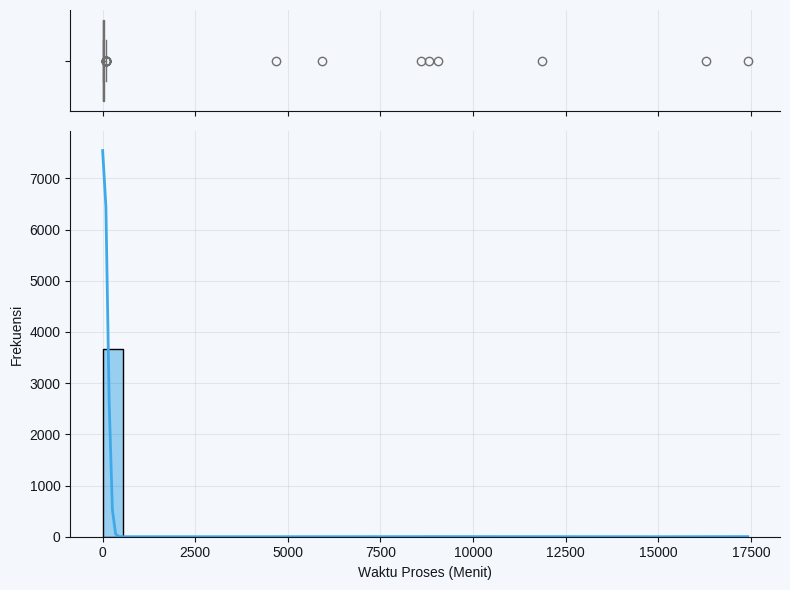

In [ ]:
fig, (ax_box, ax_hist) = plt.subplots(2, 1, figsize=(8, 6), sharex=True, gridspec_kw={'height_ratios': [0.2, 0.8]})
sns.boxplot(x=df['waktu_proses_menit'], ax=ax_box, color='skyblue')
ax_box.set(xlabel='')

sns.histplot(df['waktu_proses_menit'], kde=True, ax=ax_hist, bins=32, color=furina_bubble["pneuma_cyan"])
ax_hist.set_xlabel('Waktu Proses (Menit)')
ax_hist.set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

In [ ]:
q1 = df['waktu_proses_menit'].quantile(0.25)
q3 = df['waktu_proses_menit'].quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr

print(f"Q1: {q1:.1f}m | Q3: {q3:.1f}m | IQR: {iqr:.1f}m")
print(f"Tukey Upper Fence: {upper_fence:.1f}m")

Q1: 12.7m | Q3: 40.6m | IQR: 27.9m
Tukey Upper Fence: 82.5m


In [ ]:
df_normal = df[df['waktu_proses_menit'] <= 82.5].copy()
df_delayed = df[df['waktu_proses_menit'] > 82.5].copy()

print(f"Normal (<= 82.5m): {len(df_normal)} ({len(df_normal)/len(df):.1%})")
print(f"Delayed (> 82.5m): {len(df_delayed)} ({len(df_delayed)/len(df):.1%})")

Normal (<= 82.5m): 3646 (99.3%)
Delayed (> 82.5m): 26 (0.7%)


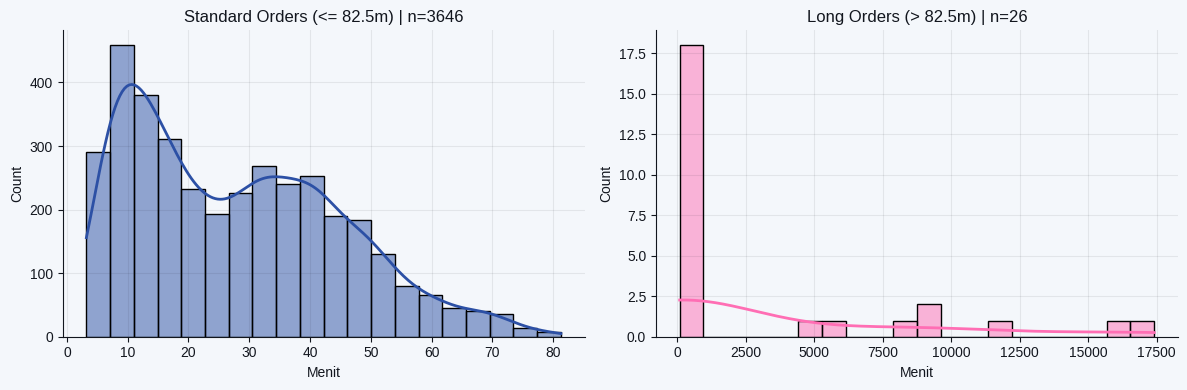

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_normal['waktu_proses_menit'], kde=True, ax=axes[0], color=furina_bubble["royal_blue"], bins=20)
axes[0].set_title(f"Standard Orders (<= 82.5m) | n={len(df_normal)}")
axes[0].set_xlabel('Menit')

sns.histplot(df_delayed['waktu_proses_menit'], kde=True, ax=axes[1], color=furina_bubble["elysian_pink"], bins=20)
axes[1].set_title(f"Long Orders (> 82.5m) | n={len(df_delayed)}")
axes[1].set_xlabel('Menit')

plt.tight_layout()
plt.show()

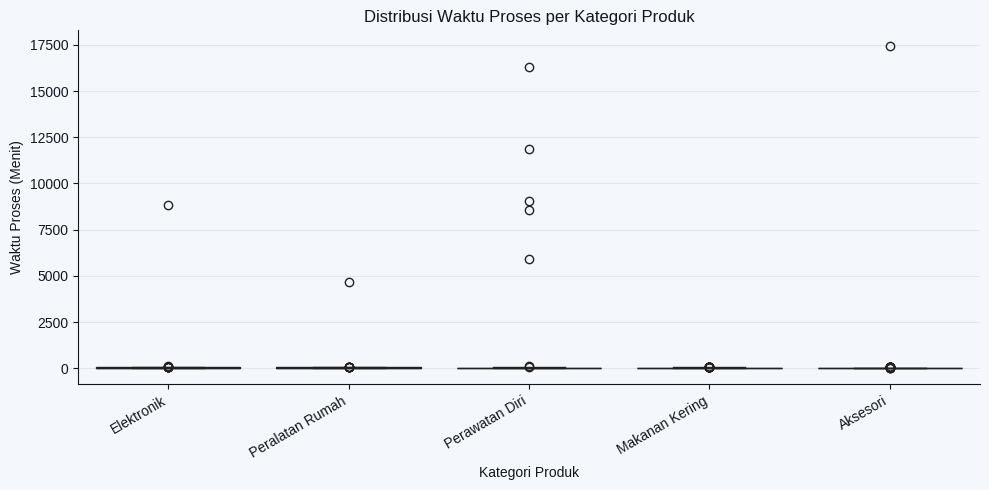

In [ ]:
order = (
    df.groupby('kategori_produk')['waktu_proses_menit']
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x='kategori_produk',
    y='waktu_proses_menit',
    order=order,
    palette= categorical_palette
)
plt.xticks(rotation=30, ha='right')
plt.xlabel('Kategori Produk')
plt.ylabel('Waktu Proses (Menit)')
plt.title('Distribusi Waktu Proses per Kategori Produk')
plt.tight_layout()
plt.show()

In [ ]:
stats = df.groupby('kategori_produk')['waktu_proses_menit'].agg(
    count='count',
    median='median',
    mean='mean',
    std='std',
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75),
    iqr=lambda x: x.quantile(0.75) - x.quantile(0.25),
    pct_over_60=lambda x: (x > 60).mean() * 100
).sort_values(by='median', ascending=False)

print(stats.to_string())

                 count  median       mean         std     q25     q75    iqr  pct_over_60
kategori_produk                                                                          
Elektronik         534   39.05  55.903745  379.942713  29.525  49.725  20.20     9.737828
Peralatan Rumah    744   37.10  42.793952  170.919667  26.500  46.700  20.20     7.930108
Perawatan Diri     924   27.20  84.497294  800.434582  12.575  41.425  28.85     6.385281
Makanan Kering     883   16.20  21.038958   15.002669  10.150  29.150  19.00     2.378256
Aksesori           587   14.00  47.296763  718.029449   9.300  22.400  13.10     0.681431


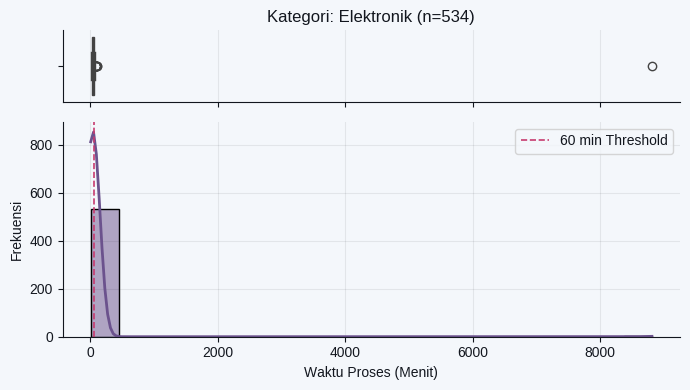

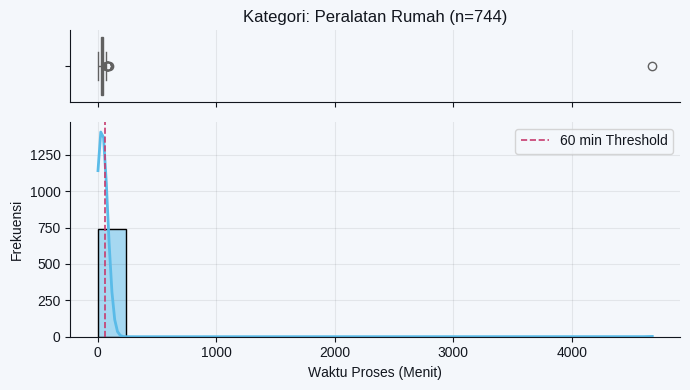

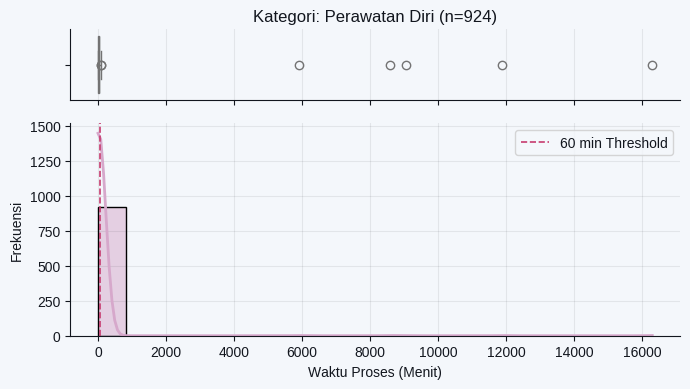

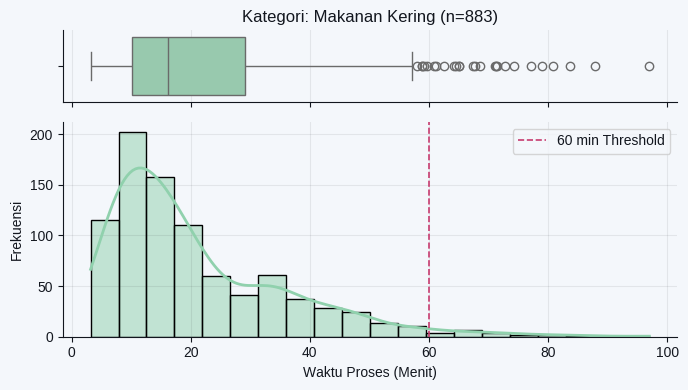

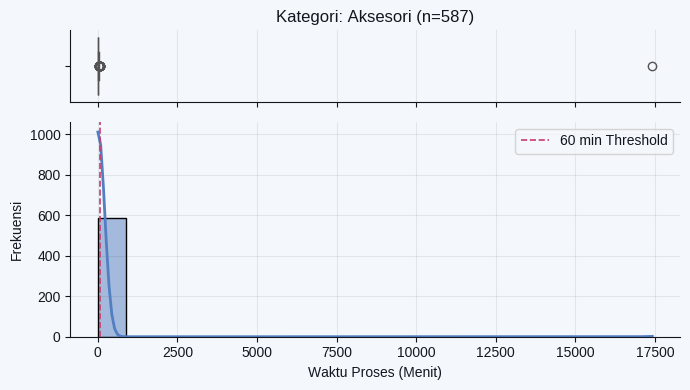

In [ ]:
categories = (
    df.groupby('kategori_produk')['waktu_proses_menit']
    .median()
    .sort_values(ascending=False)
    .index.tolist()
)

n_cats = len(categories)
cmap = mcolors.LinearSegmentedColormap.from_list("furina_blues", days_palette)
blue_shades = [mcolors.to_hex(cmap(i)) for i in np.linspace(0, 0.85, n_cats)]
category_palette = dict(zip(categories, blue_shades))

for cat in categories:
    subset = df[df['kategori_produk'] == cat]
    color = category_palette[cat]
    
    fig, (ax_box, ax_hist) = plt.subplots(
        2, 1, figsize=(7, 4), sharex=True, gridspec_kw={'height_ratios': [0.25, 0.75]}
    )
    
    sns.boxplot(x=subset['waktu_proses_menit'], ax=ax_box, color=color)
    ax_box.set(xlabel='', title=f"Kategori: {cat} (n={len(subset)})")
    
    sns.histplot(subset['waktu_proses_menit'], kde=True, ax=ax_hist, color=color, bins=20)
    ax_hist.axvline(82.5, color="#C73B6F", linestyle="--", linewidth=1.2, label="82.5 min Threshold")
    ax_hist.set_xlabel("Waktu Proses (Menit)")
    ax_hist.set_ylabel("Frekuensi")
    ax_hist.legend(loc="upper right")
    
    plt.tight_layout()
    plt.show()

Lets treat the weird process time as an outlier

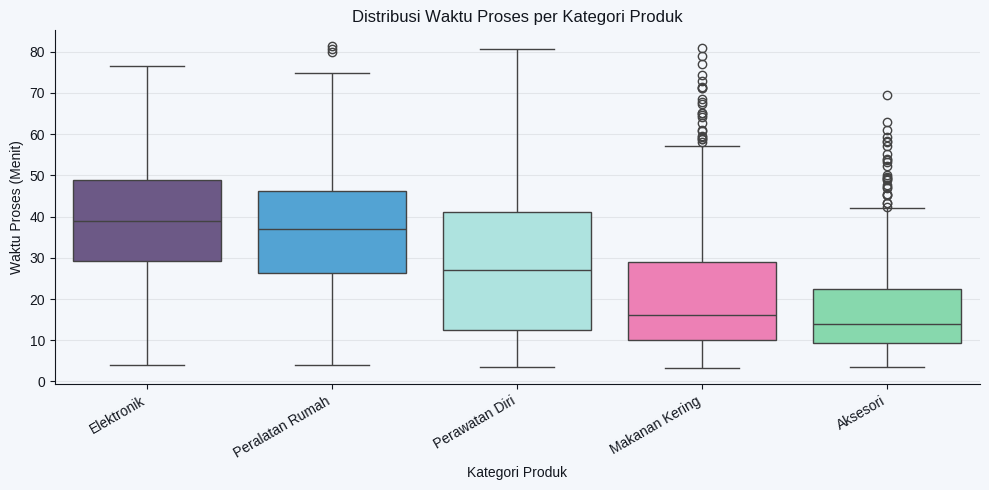

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df_normal,
    x='kategori_produk',
    y='waktu_proses_menit',
    order=order,
    palette= days_palette
)
plt.xticks(rotation=30, ha='right')
plt.xlabel('Kategori Produk')
plt.ylabel('Waktu Proses (Menit)')
plt.title('Distribusi Waktu Proses per Kategori Produk')
plt.tight_layout()
plt.show()

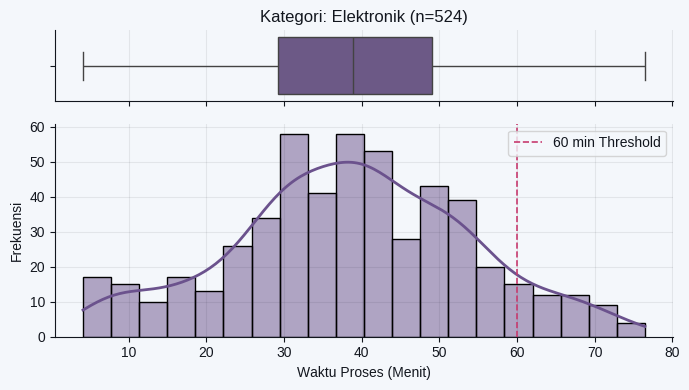

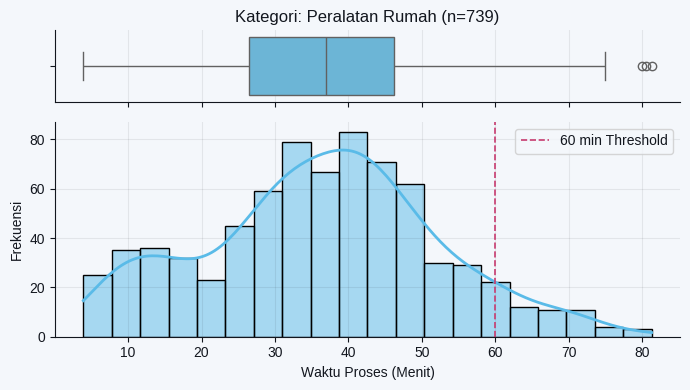

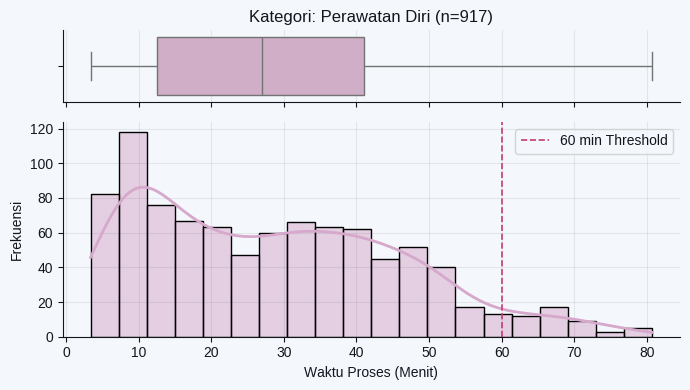

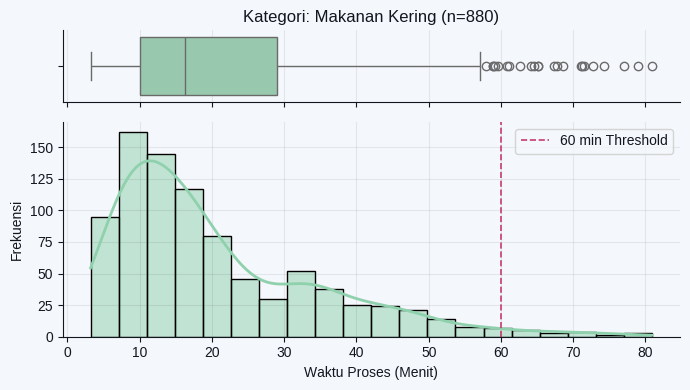

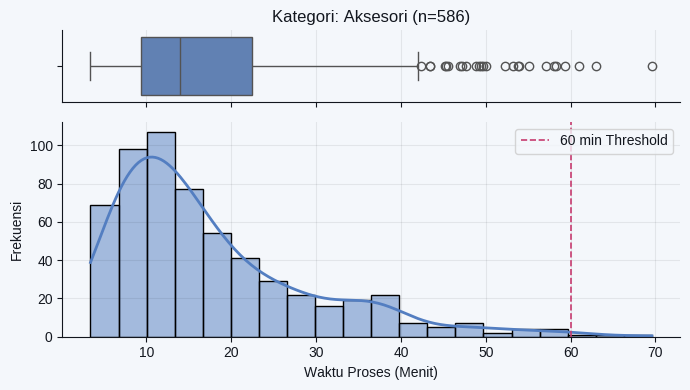

In [ ]:
cmap = mcolors.LinearSegmentedColormap.from_list("furina_blues", days_palette)
blue_shades = [mcolors.to_hex(cmap(i)) for i in np.linspace(0, 0.85, n_cats)]
category_palette = dict(zip(categories, blue_shades))

for cat in categories:
    subset = df_normal[df_normal['kategori_produk'] == cat]
    color = category_palette[cat]
    
    fig, (ax_box, ax_hist) = plt.subplots(
        2, 1, figsize=(7, 4), sharex=True, gridspec_kw={'height_ratios': [0.25, 0.75]}
    )
    
    sns.boxplot(x=subset['waktu_proses_menit'], ax=ax_box, color=color)
    ax_box.set(xlabel='', title=f"Kategori: {cat} (n={len(subset)})")
    
    sns.histplot(subset['waktu_proses_menit'], kde=True, ax=ax_hist, color=color, bins=20)
    ax_hist.axvline(60, color=furina_bubble['deep_pink'], linestyle="--", linewidth=1.2, label="60 min Threshold")
    ax_hist.set_xlabel("Waktu Proses (Menit)")
    ax_hist.set_ylabel("Frekuensi")
    ax_hist.legend(loc="upper right")
    
    plt.tight_layout()
    plt.show()

#### Why?

In [ ]:
bins = [-np.inf, 10, 20, 40, 60, np.inf]
labels = ['<10m (Fast)', '10-20m (Normal)', '20-40m (Slightly Long)', '40-60m (Long)', '>60m (Very Long)']

df['tier_waktu'] = pd.cut(
    df['waktu_proses_menit'],
    bins=bins,
    labels=labels,
    right=True
)

print(df['tier_waktu'].value_counts(sort=False))

tier_waktu
<10m (Fast)                629
10-20m (Normal)            882
20-40m (Slightly Long)    1202
40-60m (Long)              764
>60m (Very Long)           195
Name: count, dtype: int64


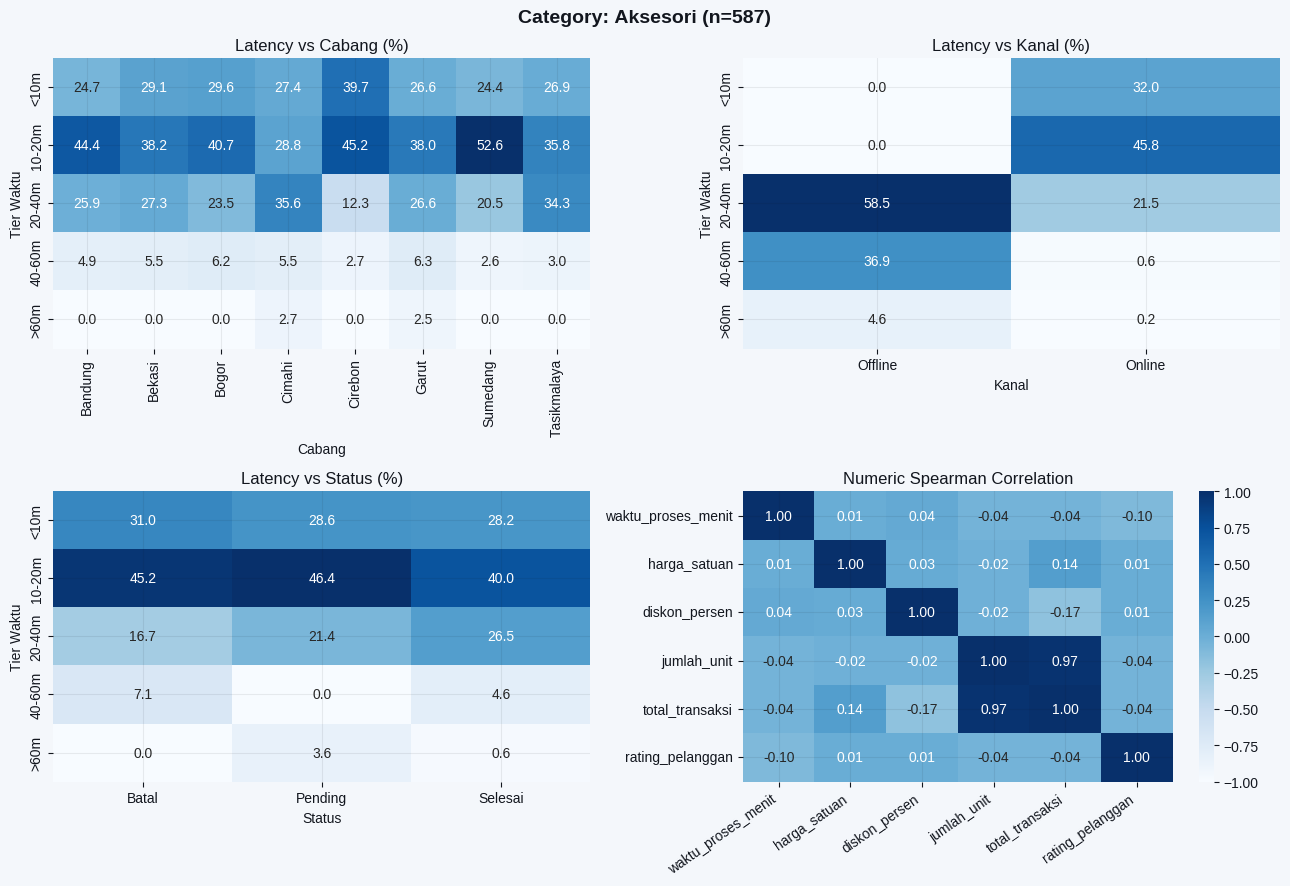

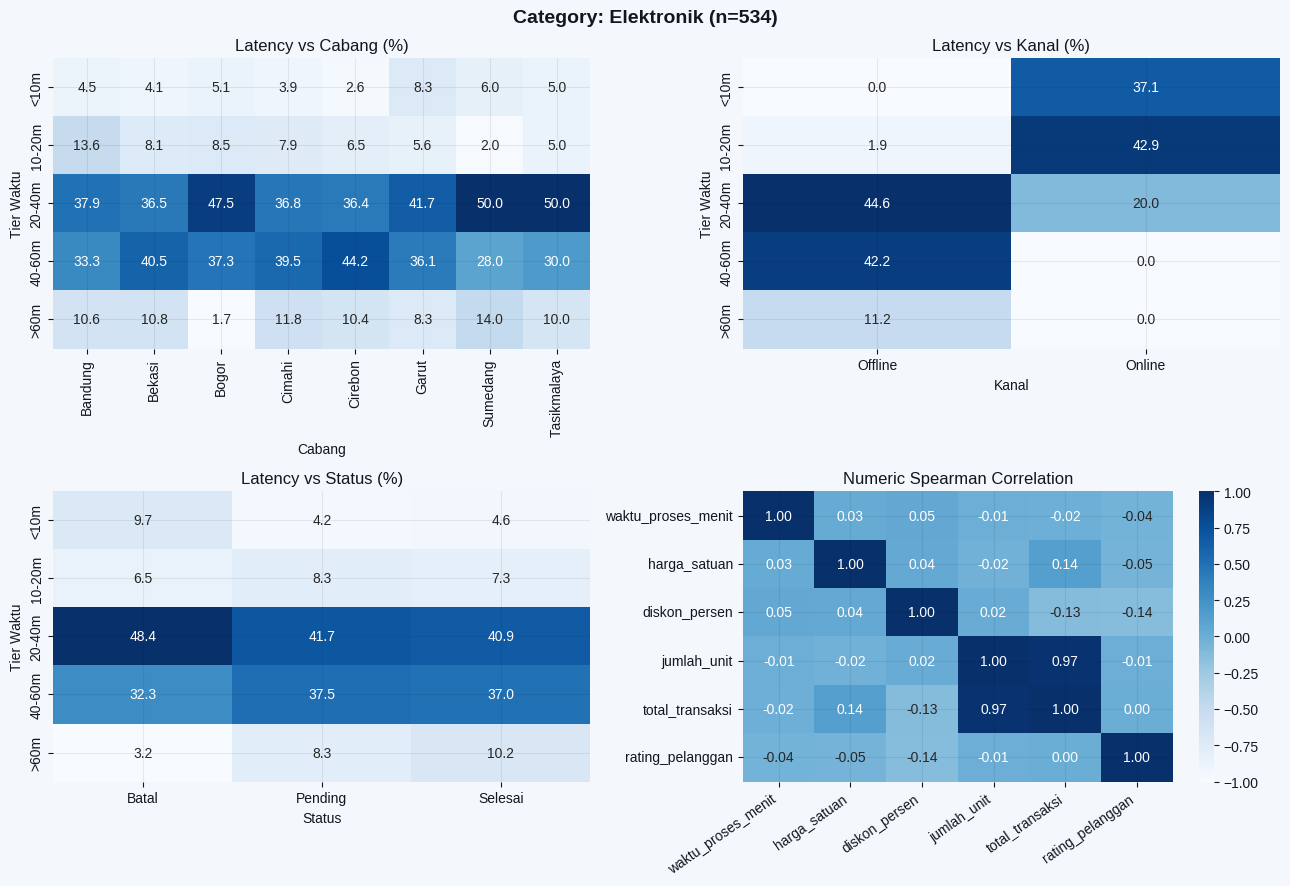

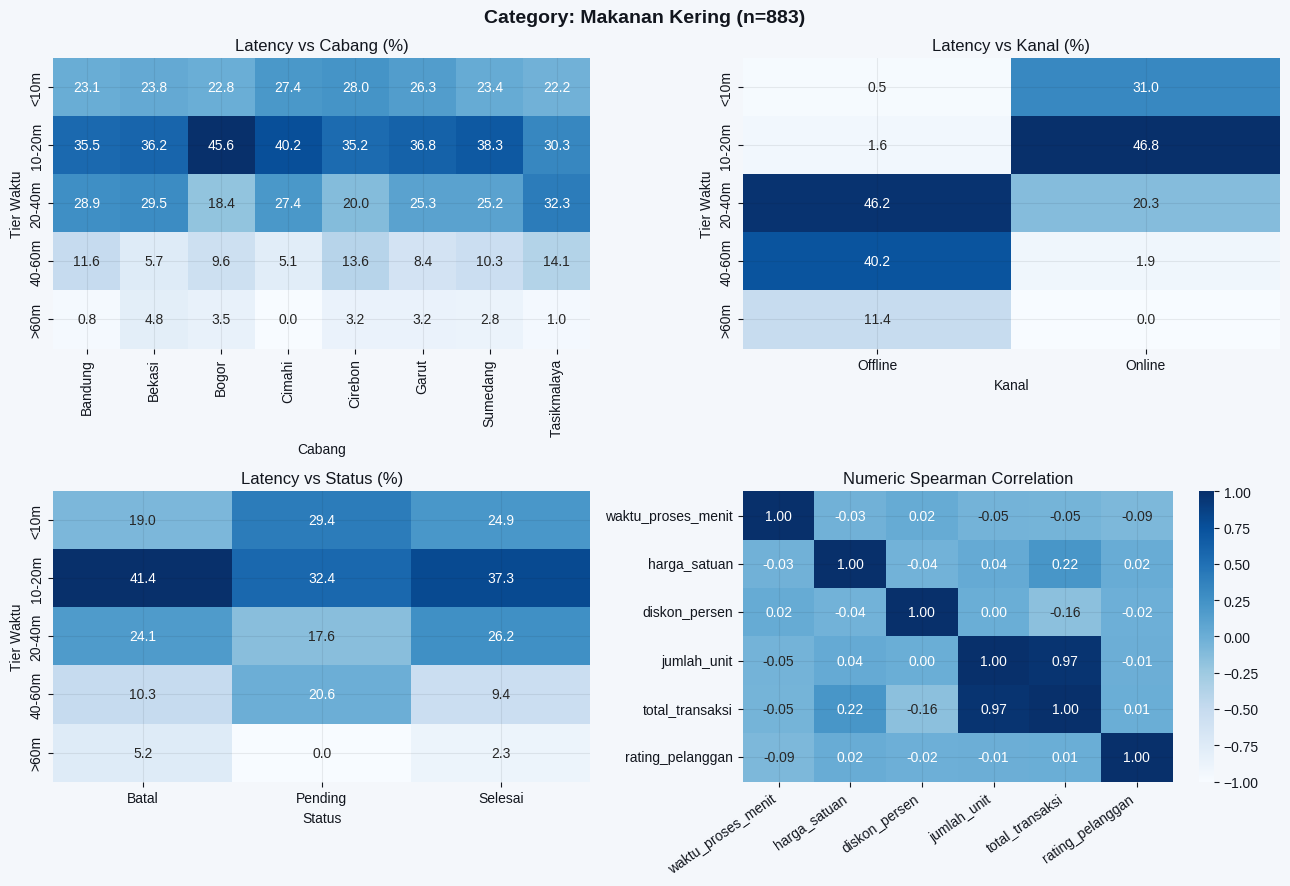

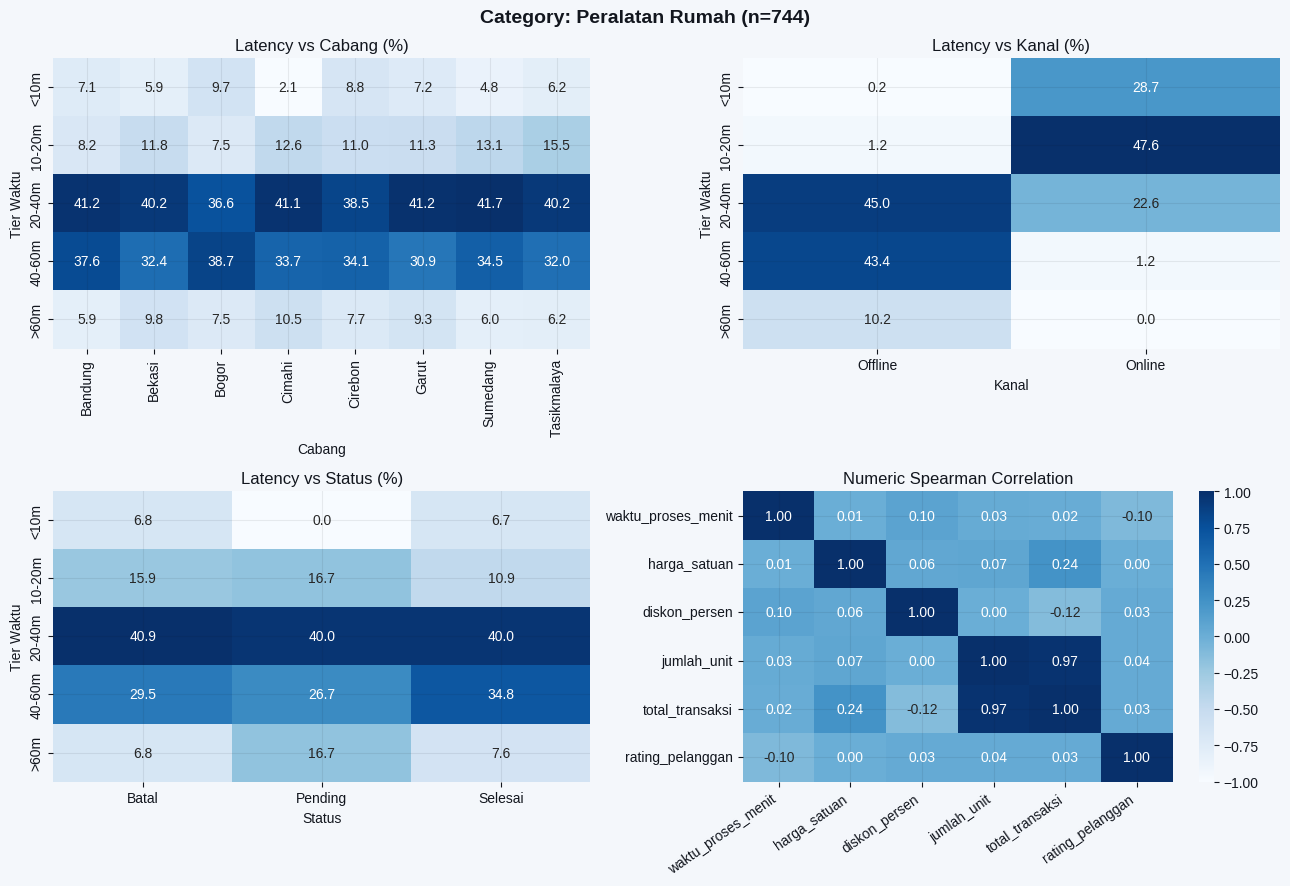

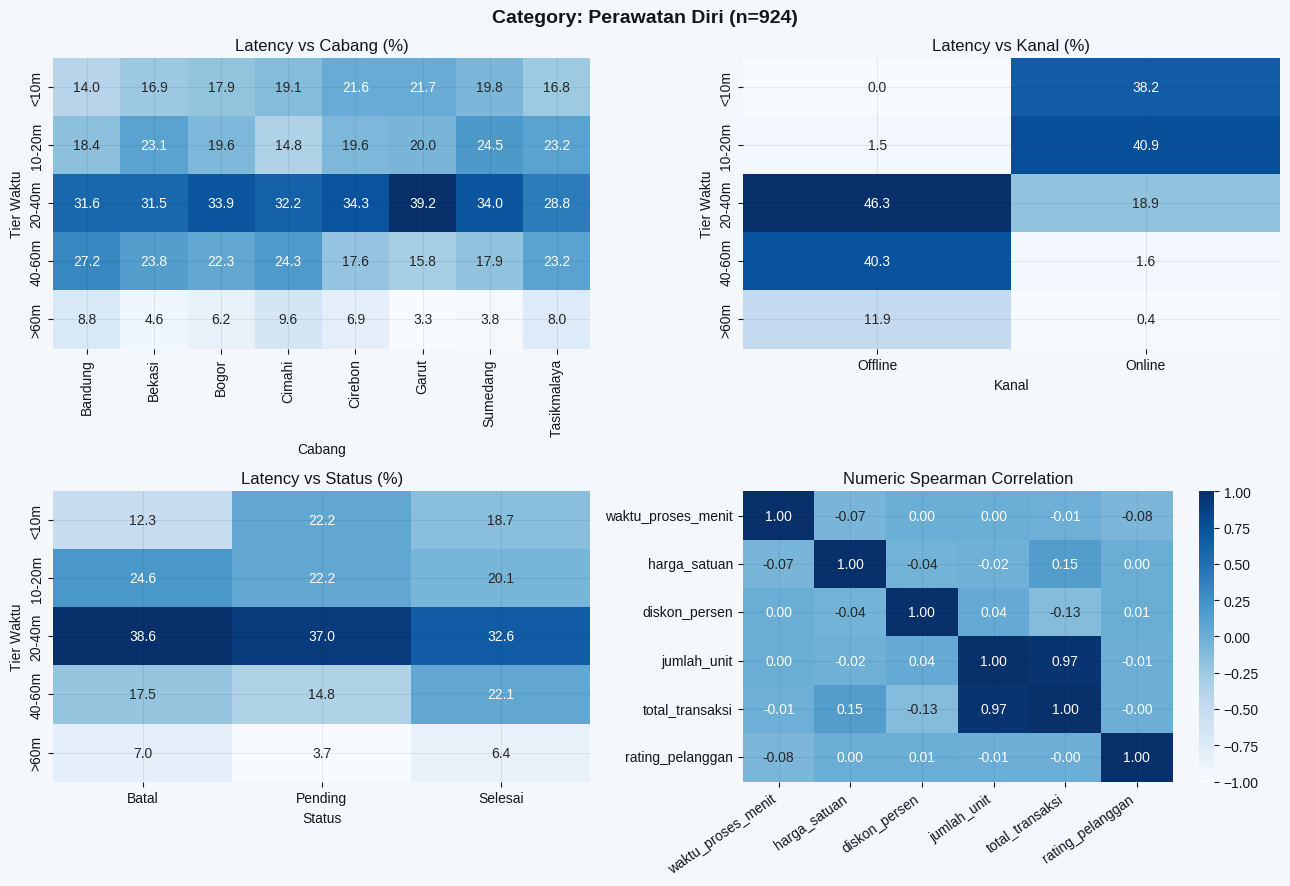

In [ ]:
labels = ['<10m', '10-20m', '20-40m', '40-60m', '>60m']

df['tier_waktu'] = pd.cut(
    df['waktu_proses_menit'],
    bins=bins,
    labels=labels,
    right=True
)

cat_features = ['cabang', 'kanal', 'status']
num_features = [
    'waktu_proses_menit',
    'harga_satuan',
    'diskon_persen',
    'jumlah_unit',
    'total_transaksi',
    'rating_pelanggan'
]

for cat_name, sub in df.groupby('kategori_produk', observed=False):
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    fig.suptitle(f"Category: {cat_name} (n={len(sub)})", fontsize=14, weight='bold')

    coords = [(0, 0), (0, 1), (1, 0)]
    for (r, c), col in zip(coords, cat_features):
        ct = pd.crosstab(sub['tier_waktu'], sub[col], normalize='columns') * 100
        ct = ct.fillna(0)
        
        sns.heatmap(
            ct,
            annot=True,
            fmt='.1f',
            cmap='Blues',
            cbar=False,
            ax=axes[r, c]
        )
        axes[r, c].set_title(f"Latency vs {col.title()} (%)")
        axes[r, c].set_xlabel(col.title())
        axes[r, c].set_ylabel("Tier Waktu")

    corr = sub[num_features].corr(method='spearman')
    
    sns.heatmap(
        corr,
        annot=True,
        fmt='.2f',
        cmap='Blues',
        vmin=-1,
        vmax=1,
        cbar=True,
        ax=axes[1, 1]
    )
    axes[1, 1].set_title("Numeric Spearman Correlation")
    axes[1, 1].set_xticklabels(axes[1, 1].get_xticklabels(), rotation=35, ha='right')

    plt.tight_layout()
    plt.show()

using spearman for outlier, but it is not good for disc & rating, we are using other method for them

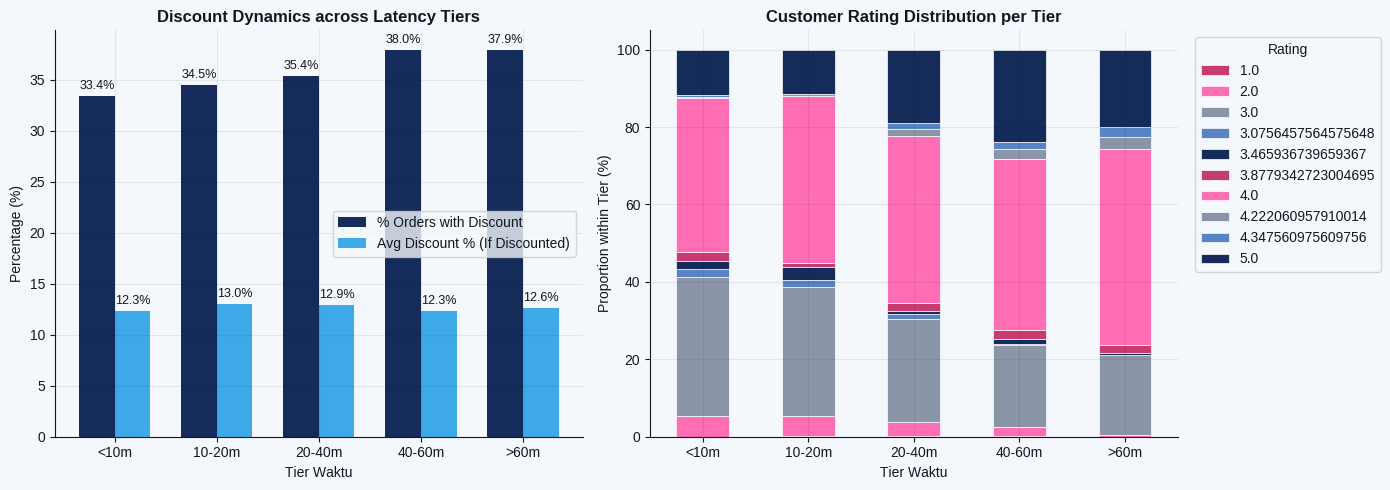

In [ ]:
df['tier_waktu'] = pd.cut(df['waktu_proses_menit'], bins=bins, labels=labels)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

disc_summary = df.groupby('tier_waktu', observed=False).apply(
    lambda g: pd.Series({
        'promo_rate': (g['diskon_persen'] > 0).mean() * 100,
        'cond_discount_mean': g.loc[g['diskon_persen'] > 0, 'diskon_persen'].mean()
    })
)

x = np.arange(len(labels))
width = 0.35

c_navy = "#152C5B"
c_cyan = "#3EA9E8"

rects1 = axes[0].bar(x - width/2, disc_summary['promo_rate'], width, label='% Orders with Discount', color=c_navy)
rects2 = axes[0].bar(x + width/2, disc_summary['cond_discount_mean'].fillna(0), width, label='Avg Discount % (If Discounted)', color=c_cyan)

axes[0].set_title('Discount Dynamics across Latency Tiers', fontsize=12, weight='bold')
axes[0].set_xlabel('Tier Waktu')
axes[0].set_ylabel('Percentage (%)')
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].legend()
axes[0].bar_label(rects1, fmt='%.1f%%', padding=3, fontsize=9)
axes[0].bar_label(rects2, fmt='%.1f%%', padding=3, fontsize=9)

rating_dist = pd.crosstab(
    df['tier_waktu'],
    df['rating_pelanggan'],
    normalize='index'
) * 100

rating_colors = [
    "#C73B6F",  # 1 star: deep_pink 
    "#FF6EB4",  # 2 star: elysian_pink
    "#8A96A8",  # 3 star: december_grey
    "#5883C4",  # 4 star: slate_blue
    "#152C5B"   # 5 star: ousia_navy
]

rating_dist.plot(
    kind='bar',
    stacked=True,
    color=rating_colors[:len(rating_dist.columns)],
    ax=axes[1],
    edgecolor='white',
    linewidth=0.5
)

axes[1].set_title('Customer Rating Distribution per Tier', fontsize=12, weight='bold')
axes[1].set_xlabel('Tier Waktu')
axes[1].set_ylabel('Proportion within Tier (%)')
axes[1].set_xticklabels(labels, rotation=0)
axes[1].legend(title='Rating', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

### 2. Apakah rating pelanggan berbeda antara kanal transaksi? Periksa jawaban Anda sekali lagi setelah memperhitungkan kategori produk — apakah kesimpulannya tetap sama?

we only need to continue the first number's visualization

In [ ]:
overall_summary = df.groupby('kanal')['rating_pelanggan'].agg(
    n='count',
    median='median',
    mean='mean',
    std='std',
    iqr=lambda x: x.quantile(0.75) - x.quantile(0.25)
).reset_index()

print("=== Rating per Kanal (Overall) ===")
print(overall_summary.to_string(index=False))

groups = [group['rating_pelanggan'].dropna().values for _, group in df.groupby('kanal')]
h_stat, p_val = stats.kruskal(*groups)

print(f"\nKruskal-Wallis: H = {h_stat:.4f}, p-value = {p_val:.4e}")

=== Rating per Kanal (Overall) ===
  kanal    n  median     mean      std      iqr
Offline 1772     4.0 3.962768 0.747449 0.344127
 Online 1900     4.0 3.626223 0.755314 1.000000

Kruskal-Wallis: H = 186.1382, p-value = 2.2148e-42


In [ ]:
stratified_summary = df.groupby(['kategori_produk', 'kanal'])['rating_pelanggan'].agg(
    n='count',
    median='median',
    mean='mean',
    iqr=lambda x: x.quantile(0.75) - x.quantile(0.25)
).reset_index()

print("\n=== Rating per Kanal per Kategori Produk ===")
print(stratified_summary.to_string(index=False))

print("\n=== Kruskal-Wallis p-values per Kategori Produk ===")
for cat, sub in df.groupby('kategori_produk'):
    sub_groups = [g['rating_pelanggan'].dropna().values for _, g in sub.groupby('kanal')]
    if len(sub_groups) > 1 and all(len(g) > 0 for g in sub_groups):
        h_val, p = stats.kruskal(*sub_groups)
        print(f"Kategori '{cat}': H={h_val:.3f}, p={p:.4f} {'(Signifikan)' if p < 0.05 else '(Tidak Signifikan)'}")


=== Rating per Kanal per Kategori Produk ===
kategori_produk   kanal   n   median     mean      iqr
       Aksesori Offline  65 3.000000 2.726568 1.000000
       Aksesori  Online 522 3.000000 3.119113 0.075646
     Elektronik Offline 464 4.000000 4.336654 1.000000
     Elektronik  Online  70 4.173780 4.419861 1.000000
 Makanan Kering Offline 184 3.000000 3.228942 1.000000
 Makanan Kering  Online 699 3.465937 3.528322 1.000000
Peralatan Rumah Offline 580 4.000000 4.169146 1.000000
Peralatan Rumah  Online 164 4.222061 4.409200 1.000000
 Perawatan Diri Offline 479 4.000000 3.800337 1.000000
 Perawatan Diri  Online 445 4.000000 3.961460 0.122066

=== Kruskal-Wallis p-values per Kategori Produk ===
Kategori 'Aksesori': H=19.662, p=0.0000 (Signifikan)
Kategori 'Elektronik': H=1.009, p=0.3151 (Tidak Signifikan)
Kategori 'Makanan Kering': H=33.998, p=0.0000 (Signifikan)
Kategori 'Peralatan Rumah': H=18.460, p=0.0000 (Signifikan)
Kategori 'Perawatan Diri': H=13.949, p=0.0002 (Signifikan)


=== Rating per Kanal (Overall) ===
  kanal    n  mean  std  median  iqr
Offline 1772  3.96 0.75     4.0 0.34
 Online 1900  3.63 0.76     4.0 1.00

ANOVA (Means):      F = 183.870, p-value = 6.5920e-41
Kruskal (Medians):  H = 186.138, p-value = 2.2148e-42

=== Rating per Kanal per Kategori Produk ===
kategori_produk   kanal   n  mean  median
       Aksesori Offline  65  2.73    3.00
       Aksesori  Online 522  3.12    3.00
     Elektronik Offline 464  4.34    4.00
     Elektronik  Online  70  4.42    4.17
 Makanan Kering Offline 184  3.23    3.00
 Makanan Kering  Online 699  3.53    3.47
Peralatan Rumah Offline 580  4.17    4.00
Peralatan Rumah  Online 164  4.41    4.22
 Perawatan Diri Offline 479  3.80    4.00
 Perawatan Diri  Online 445  3.96    4.00


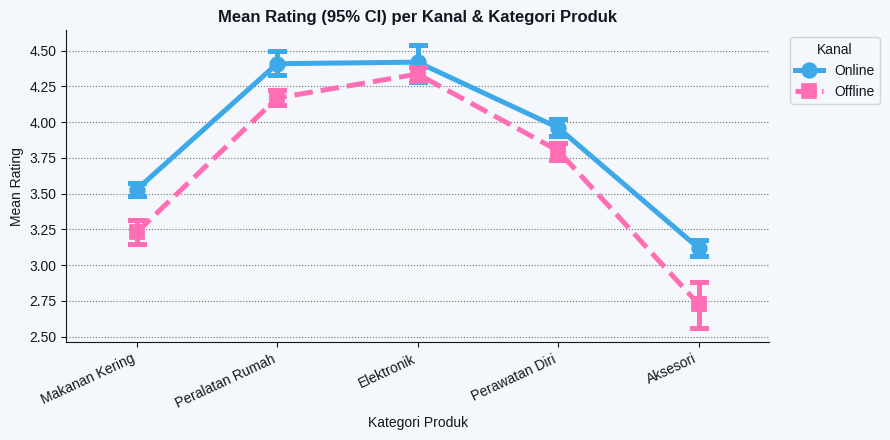

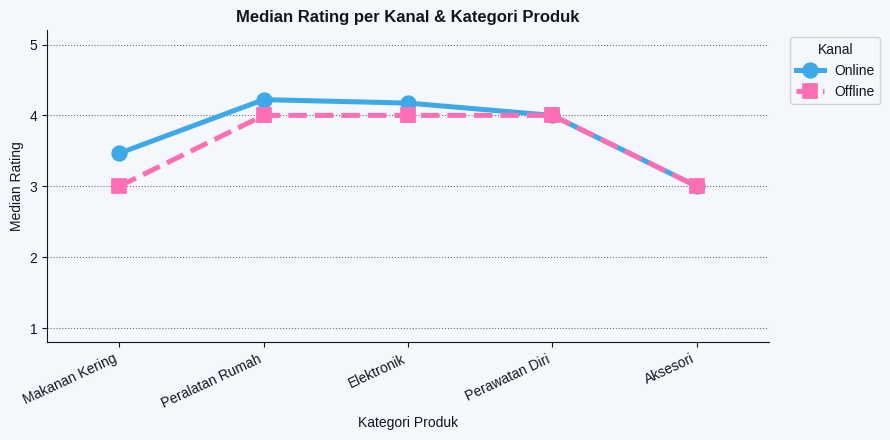

In [ ]:
overall_summary = df.groupby('kanal')['rating_pelanggan'].agg(
    n='count',
    mean='mean',
    std='std',
    median='median',
    iqr=lambda x: x.quantile(0.75) - x.quantile(0.25)
).round(2).reset_index()

print("=== Rating per Kanal (Overall) ===")
print(overall_summary.to_string(index=False))

groups = [group['rating_pelanggan'].dropna().values for _, group in df.groupby('kanal')]
f_stat, p_anova = stats.f_oneway(*groups)
h_stat, p_kw = stats.kruskal(*groups)

print(f"\nANOVA (Means):      F = {f_stat:.3f}, p-value = {p_anova:.4e}")
print(f"Kruskal (Medians):  H = {h_stat:.3f}, p-value = {p_kw:.4e}")

stratified_summary = df.groupby(['kategori_produk', 'kanal'])['rating_pelanggan'].agg(
    n='count',
    mean='mean',
    median='median'
).round(2).reset_index()

print("\n=== Rating per Kanal per Kategori Produk ===")
print(stratified_summary.to_string(index=False))

palette = ["#3EA9E8", "#FF6EB4"]

plt.figure(figsize=(9, 4.5))
sns.pointplot(
    data=df,
    x="kategori_produk",
    y="rating_pelanggan",
    hue="kanal",
    estimator="mean",
    errorbar=("ci", 95),
    capsize=0.1,
    markers=["o", "s", "D"],
    linestyles=["-", "--", "-."],
    palette=palette
)
plt.title("Mean Rating (95% CI) per Kanal & Kategori Produk", weight="bold")
plt.xlabel("Kategori Produk")
plt.ylabel("Mean Rating")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.legend(title="Kanal", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


plt.figure(figsize=(9, 4.5))
sns.pointplot(
    data=df,
    x="kategori_produk",
    y="rating_pelanggan",
    hue="kanal",
    estimator="median",
    errorbar=None,
    markers=["o", "s", "D"],
    linestyles=["-", "--", "-."],
    palette=palette
)
plt.title("Median Rating per Kanal & Kategori Produk", weight="bold")
plt.xlabel("Kategori Produk")
plt.ylabel("Median Rating")
plt.ylim(0.8, 5.2)
plt.yticks([1, 2, 3, 4, 5], labels=["1", "2", "3", "4", "5"])
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.legend(title="Kanal", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [ ]:
df[df['rating_pelanggan'] > 5].shape[0]

0

In [ ]:
df[df['rating_pelanggan'].isnull()].shape[0]

0

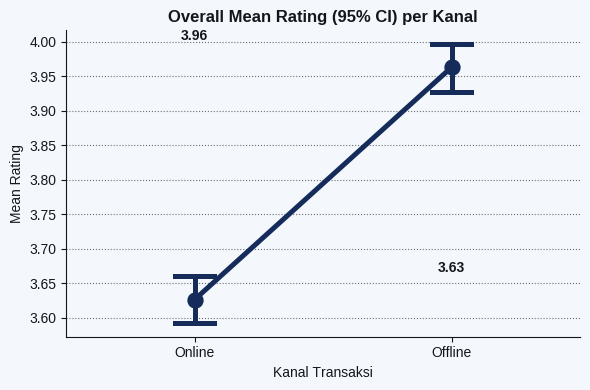

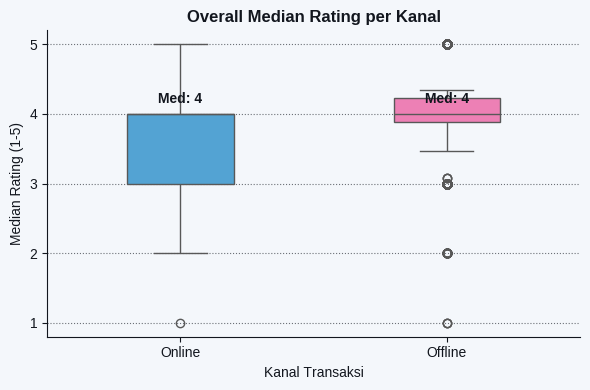

In [ ]:
palette = ["#3EA9E8", "#FF6EB4"]

plt.figure(figsize=(6, 4))
ax_mean = sns.pointplot(
    data=df,
    x="kanal",
    y="rating_pelanggan",
    estimator="mean",
    errorbar=("ci", 95),
    capsize=0.15,
    markers="o",
    linestyles="-",
    color="#152C5B"
)

means = df.groupby("kanal")["rating_pelanggan"].mean()
for idx, (kanal_name, mean_val) in enumerate(means.items()):
    ax_mean.text(idx, mean_val + 0.04, f"{mean_val:.2f}", ha="center", weight="bold", fontsize=10)

plt.title("Overall Mean Rating (95% CI) per Kanal", weight="bold")
plt.xlabel("Kanal Transaksi")
plt.ylabel("Mean Rating")
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
ax_med = sns.boxplot(
    data=df,
    x="kanal",
    y="rating_pelanggan",
    palette=palette,
    width=0.4,
    showmeans=False
)

medians = df.groupby("kanal")["rating_pelanggan"].median()
for idx, (kanal_name, med_val) in enumerate(medians.items()):
    ax_med.text(idx, med_val + 0.15, f"Med: {int(med_val)}", ha="center", weight="bold", color="#12161E")

plt.title("Overall Median Rating per Kanal", weight="bold")
plt.xlabel("Kanal Transaksi")
plt.ylabel("Median Rating (1-5)")
plt.ylim(0.8, 5.2)
plt.yticks([1, 2, 3, 4, 5], labels=["1", "2", "3", "4", "5"])
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

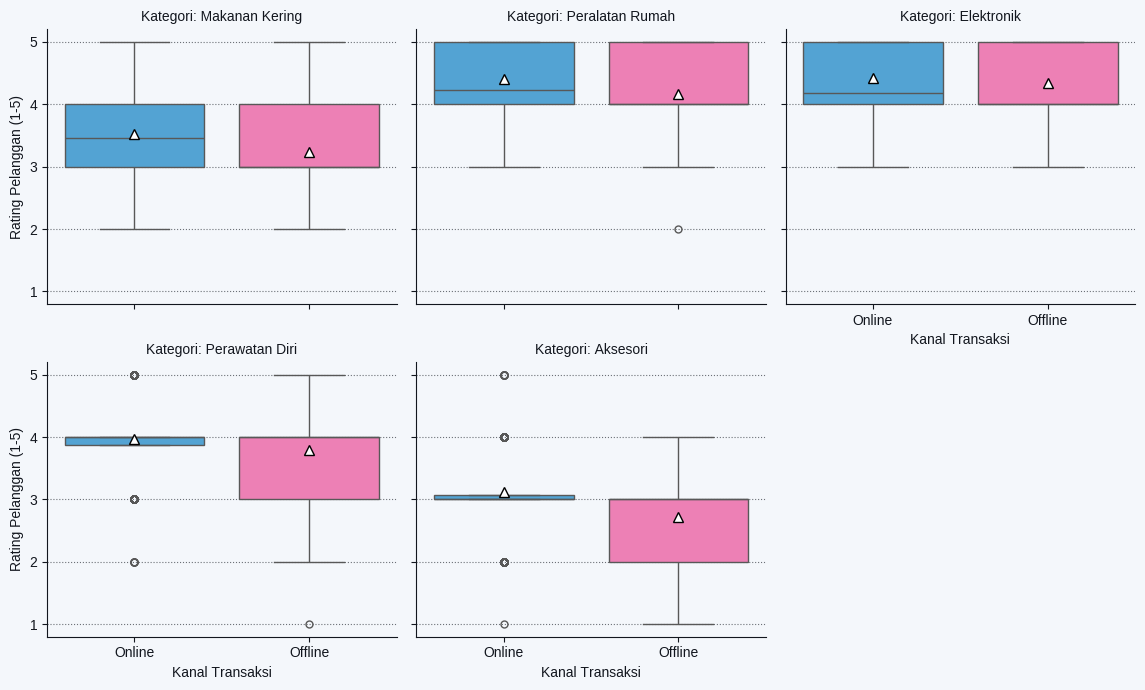

In [ ]:
g = sns.catplot(
    data=df,
    x="kanal",
    y="rating_pelanggan",
    col="kategori_produk",
    col_wrap=3,
    kind="box",
    palette=[ "#3EA9E8", "#FF6EB4", "#8A96A8",],
    height=3.5,
    aspect=1.1,
    showmeans=True,
    meanprops={
        "marker": "^",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": 7
    }
)

g.set_axis_labels("Kanal Transaksi", "Rating Pelanggan (1-5)")
g.set_titles(col_template="Kategori: {col_name}")
g.set(ylim=(0.8, 5.2), yticks=[1, 2, 3, 4, 5])

for ax in g.axes.flat:
    ax.grid(axis="y", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

#### Extra experiment for anova

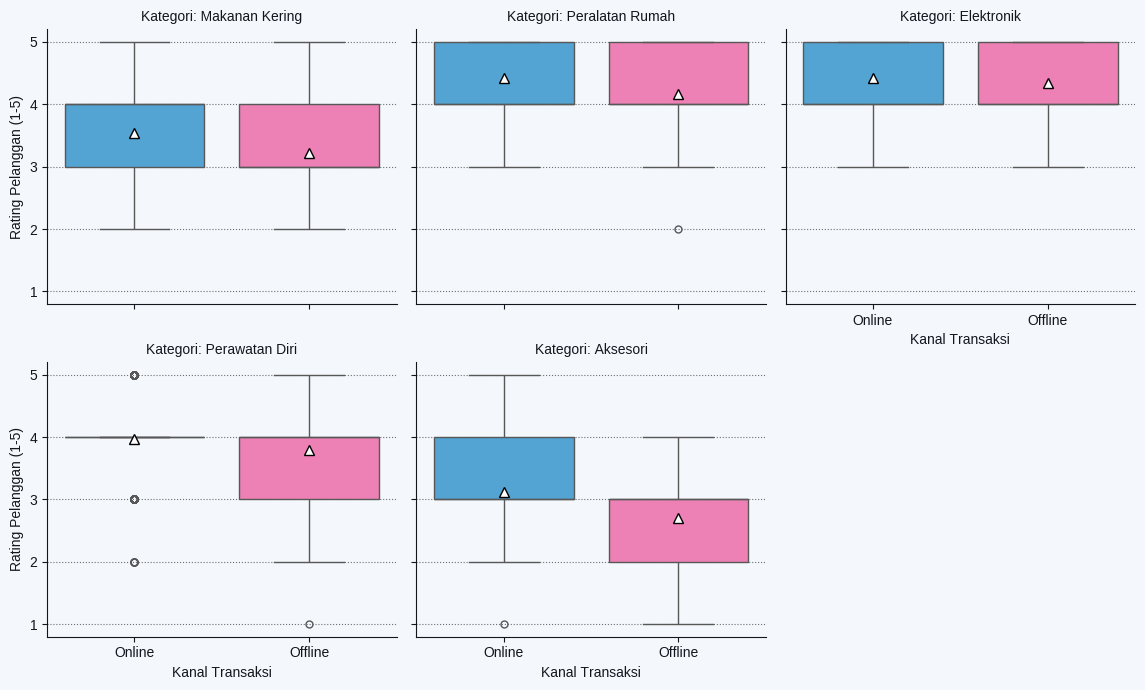

In [ ]:
g = sns.catplot(
    data=df_forlast,
    x="kanal",
    y="rating_pelanggan",
    col="kategori_produk",
    col_wrap=3,
    kind="box",
    palette=[ "#3EA9E8", "#FF6EB4", "#8A96A8",],
    height=3.5,
    aspect=1.1,
    showmeans=True,
    meanprops={
        "marker": "^",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": 7
    }
)

g.set_axis_labels("Kanal Transaksi", "Rating Pelanggan (1-5)")
g.set_titles(col_template="Kategori: {col_name}")
g.set(ylim=(0.8, 5.2), yticks=[1, 2, 3, 4, 5])

for ax in g.axes.flat:
    ax.grid(axis="y", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()